# Lab Exercise 3 — Graph RAG over the Neo4j Movies Knowledge Graph
**Advance NLP (AML23702) · Department of AIML**

**Aim.** Build a small Retrieval-Augmented Generation (RAG) application that uses the **Neo4j Movies dataset** as its knowledge-graph backend. It turns user questions into **Cypher queries**, retrieves movie, actor and director facts from the graph, and uses an **LLM** to write grounded natural-language answers, including simple recommendations.

**Pipeline:** question → entity linking against the graph → intent routing to a **Cypher query template** (or LLM text-to-Cypher for questions no template covers) → Cypher retrieval from Neo4j → retrieved facts → LLM answer grounded only in those facts → groundedness check.

| Expected outcome (lab sheet) | Where in this notebook |
|---|---|
| Load and use the Neo4j movie graph | §1 connection and loading, §2 knowledge-graph schema |
| Convert user questions into graph queries | §3 Cypher templates, §4 entity linking and routing, §5 LLM text-to-Cypher |
| Retrieve relevant movie and actor data | §3 templates executed by `retrieve()` |
| Generate grounded natural-language answers | §6 grounded generation and groundedness check |
| Basic movie QA and recommendations | §7 RAG pipeline, demo conversations and chat loop |
| Deliverables: Neo4j instance, Cypher templates, RAG prototype, report | §1, §3 (also saved to `outputs/cypher_templates.cypher`), §7, §8 evaluation |

### How to run
1. **Neo4j.** Create a free **Neo4j AuraDB Free** instance at console.neo4j.io (or a local database in **Neo4j Desktop**). Note its connection URI, username and password.
2. **LLM.** Get an API key from any supported provider: `groq`, `gemini`, `openai` or `anthropic`. For a fully local model, use `ollama` with no key.
3. Set the environment variables before starting Jupyter (or type the values into the configuration cell below):
   `NEO4J_URI`, `NEO4J_USERNAME`, `NEO4J_PASSWORD`, `LLM_PROVIDER`, `LLM_API_KEY`, and optionally `LLM_MODEL`.
4. `Kernel → Restart & Run All`. On first run the notebook loads the Movies dataset into Neo4j.

**Offline mode.** If no Neo4j URI is set, the notebook still runs. It builds the same graph in memory from the same Cypher script and answers template questions with Python equivalents of each Cypher template. If no LLM is configured, answers come from a deterministic template-based writer instead of the LLM, and LLM text-to-Cypher is skipped. The banner printed below always states which mode produced the outputs.

In [22]:
# 0. Setup: install anything missing (safe to re-run)
import importlib.util, subprocess, sys
PACKAGES = {"neo4j": "neo4j>=5.14", "requests": "requests", "pandas": "pandas", "matplotlib": "matplotlib",
            "networkx": "networkx"}
missing = [pip for mod, pip in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("environment ready")

environment ready


In [23]:
import ast, difflib, json, os, re, time
from collections import Counter, defaultdict, deque
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 100)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

# ------------------------------------------------------------------ configuration
# Put your values as the SECOND argument of os.getenv(...). Never commit real passwords or keys to GitHub.
NEO4J_URI      = os.getenv("NEO4J_URI", "").strip()            # e.g. neo4j+s://xxxxxxxx.databases.neo4j.io  or  neo4j://localhost:7687
NEO4J_USERNAME = os.getenv("NEO4J_USERNAME", "").strip()
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD", "").strip()
NEO4J_DATABASE = os.getenv("NEO4J_DATABASE", "").strip() or None   # empty = the server's default database
LLM_PROVIDER   = os.getenv("LLM_PROVIDER", "").strip().lower()  # groq | gemini | openai | ollama | anthropic | "" (none)
LLM_API_KEY    = os.getenv("LLM_API_KEY", "").strip()
LLM_MODEL      = os.getenv("LLM_MODEL", "").strip()             # leave "" to pick automatically

LLM_PRESETS = {  # provider -> (base URL, preferred models in order). All except anthropic speak the OpenAI chat API.
    "groq":      ("https://api.groq.com/openai/v1", ["openai/gpt-oss-120b", "llama-3.3-70b-versatile", "openai/gpt-oss-20b", "llama-3.1-8b-instant"]),
    "gemini":    ("https://generativelanguage.googleapis.com/v1beta/openai", ["gemini-2.5-flash", "gemini-2.0-flash"]),
    "openai":    ("https://api.openai.com/v1", ["gpt-4o-mini"]),
    "ollama":    (os.getenv("OLLAMA_URL", "http://localhost:11434/v1"), ["llama3.1"]),
    "anthropic": ("https://api.anthropic.com/v1", ["claude-haiku-5-5"]),
}
NOT_CHAT = ("whisper", "guard", "safeguard", "tts", "orpheus", "distil", "embed")

def pick_llm_model():
    """Return the first model this key can actually chat with (tests each candidate with a tiny request)."""
    base, preferred = LLM_PRESETS[LLM_PROVIDER]
    if LLM_PROVIDER == "anthropic":
        return LLM_MODEL or preferred[0]
    headers = {"Authorization": f"Bearer {LLM_API_KEY}"} if LLM_API_KEY else {}
    r = requests.get(f"{base}/models", headers=headers, timeout=20)
    if r.status_code in (401, 403):
        raise RuntimeError(f"{LLM_PROVIDER} rejected the API key ({r.status_code}): copy the key again, without spaces")
    available = [m["id"].replace("models/", "") for m in r.json().get("data", [])] if r.ok else []
    candidates = ([LLM_MODEL] if LLM_MODEL else []) + [m for m in preferred if not available or m in available] + \
                 [m for m in available if not any(x in m for x in NOT_CHAT)]
    for m in dict.fromkeys(candidates):
        t = requests.post(f"{base}/chat/completions", timeout=30, headers={**headers, "Content-Type": "application/json"},
                          json={"model": m, "max_tokens": 50, "messages": [{"role": "user", "content": "Reply with OK"}]})
        if t.status_code == 200:
            return m
        print(f"  model {m} not usable ({t.status_code})")
    raise RuntimeError("no chat model available for this key")

USE_NEO4J = bool(NEO4J_URI)
USE_LLM = False
if LLM_PROVIDER in LLM_PRESETS and (LLM_API_KEY or LLM_PROVIDER == "ollama"):
    try:
        LLM_MODEL = pick_llm_model()
        USE_LLM = True
    except Exception as err:
        print(f"LLM check failed ({err}); continuing with the offline template writer.")
MODE = (f"graph: {'Neo4j at ' + NEO4J_URI if USE_NEO4J else 'OFFLINE in-memory graph (Neo4j not configured)'} | "
        f"generation: {LLM_PROVIDER + ' / ' + LLM_MODEL if USE_LLM else 'OFFLINE template writer (LLM not configured)'}")
print("RUN MODE ->", MODE)

RUN MODE -> graph: Neo4j at neo4j+s://42668041.databases.neo4j.io | generation: groq / openai/gpt-oss-120b


In [24]:
# Official Neo4j Movies dataset (neo4j-graph-examples/movies, scripts/movies.cypher), embedded verbatim
MOVIES_CYPHER = r'''CREATE CONSTRAINT movie_title IF NOT EXISTS FOR (m:Movie) REQUIRE m.title IS UNIQUE;
CREATE CONSTRAINT person_name IF NOT EXISTS FOR (p:Person) REQUIRE p.name IS UNIQUE;

MERGE (TheMatrix:Movie {title:'The Matrix'}) ON CREATE SET TheMatrix.released=1999, TheMatrix.tagline='Welcome to the Real World'

MERGE (Keanu:Person {name:'Keanu Reeves'}) ON CREATE SET Keanu.born=1964
MERGE (Carrie:Person {name:'Carrie-Anne Moss'}) ON CREATE SET Carrie.born=1967
MERGE (Laurence:Person {name:'Laurence Fishburne'}) ON CREATE SET Laurence.born=1961
MERGE (Hugo:Person {name:'Hugo Weaving'}) ON CREATE SET Hugo.born=1960
MERGE (LillyW:Person {name:'Lilly Wachowski'}) ON CREATE SET LillyW.born=1967
MERGE (LanaW:Person {name:'Lana Wachowski'}) ON CREATE SET LanaW.born=1965
MERGE (JoelS:Person {name:'Joel Silver'}) ON CREATE SET JoelS.born=1952

MERGE (Keanu)-[:ACTED_IN {roles:['Neo']}]->(TheMatrix)
MERGE (Carrie)-[:ACTED_IN {roles:['Trinity']}]->(TheMatrix)
MERGE (Laurence)-[:ACTED_IN {roles:['Morpheus']}]->(TheMatrix)
MERGE (Hugo)-[:ACTED_IN {roles:['Agent Smith']}]->(TheMatrix)
MERGE (LillyW)-[:DIRECTED]->(TheMatrix)
MERGE (LanaW)-[:DIRECTED]->(TheMatrix)
MERGE (JoelS)-[:PRODUCED]->(TheMatrix)

MERGE (Emil:Person {name:'Emil Eifrem'}) ON CREATE SET Emil.born=1978
MERGE (Emil)-[:ACTED_IN {roles:["Emil"]}]->(TheMatrix);


MERGE (TheMatrixReloaded:Movie {title:'The Matrix Reloaded'}) ON CREATE SET TheMatrixReloaded.released=2003, TheMatrixReloaded.tagline='Free your mind'

MERGE (Keanu:Person {name:'Keanu Reeves'}) ON CREATE SET Keanu.born=1964
MERGE (Carrie:Person {name:'Carrie-Anne Moss'}) ON CREATE SET Carrie.born=1967
MERGE (Laurence:Person {name:'Laurence Fishburne'}) ON CREATE SET Laurence.born=1961
MERGE (Hugo:Person {name:'Hugo Weaving'}) ON CREATE SET Hugo.born=1960
MERGE (LillyW:Person {name:'Lilly Wachowski'}) ON CREATE SET LillyW.born=1967
MERGE (LanaW:Person {name:'Lana Wachowski'}) ON CREATE SET LanaW.born=1965
MERGE (JoelS:Person {name:'Joel Silver'}) ON CREATE SET JoelS.born=1952

MERGE (Keanu)-[:ACTED_IN {roles:['Neo']}]->(TheMatrixReloaded)
MERGE (Carrie)-[:ACTED_IN {roles:['Trinity']}]->(TheMatrixReloaded)
MERGE (Laurence)-[:ACTED_IN {roles:['Morpheus']}]->(TheMatrixReloaded)
MERGE (Hugo)-[:ACTED_IN {roles:['Agent Smith']}]->(TheMatrixReloaded)
MERGE (LillyW)-[:DIRECTED]->(TheMatrixReloaded)
MERGE (LanaW)-[:DIRECTED]->(TheMatrixReloaded)
MERGE (JoelS)-[:PRODUCED]->(TheMatrixReloaded);


MERGE (TheMatrixRevolutions:Movie {title:'The Matrix Revolutions'}) ON CREATE SET TheMatrixRevolutions.released=2003, TheMatrixRevolutions.tagline='Everything that has a beginning has an end'

MERGE (Keanu:Person {name:'Keanu Reeves'}) ON CREATE SET Keanu.born=1964
MERGE (Carrie:Person {name:'Carrie-Anne Moss'}) ON CREATE SET Carrie.born=1967
MERGE (Laurence:Person {name:'Laurence Fishburne'}) ON CREATE SET Laurence.born=1961
MERGE (Hugo:Person {name:'Hugo Weaving'}) ON CREATE SET Hugo.born=1960
MERGE (LillyW:Person {name:'Lilly Wachowski'}) ON CREATE SET LillyW.born=1967
MERGE (LanaW:Person {name:'Lana Wachowski'}) ON CREATE SET LanaW.born=1965
MERGE (JoelS:Person {name:'Joel Silver'}) ON CREATE SET JoelS.born=1952

MERGE (Keanu)-[:ACTED_IN {roles:['Neo']}]->(TheMatrixRevolutions)
MERGE (Carrie)-[:ACTED_IN {roles:['Trinity']}]->(TheMatrixRevolutions)
MERGE (Laurence)-[:ACTED_IN {roles:['Morpheus']}]->(TheMatrixRevolutions)
MERGE (Hugo)-[:ACTED_IN {roles:['Agent Smith']}]->(TheMatrixRevolutions)
MERGE (LillyW)-[:DIRECTED]->(TheMatrixRevolutions)
MERGE (LanaW)-[:DIRECTED]->(TheMatrixRevolutions)
MERGE (JoelS)-[:PRODUCED]->(TheMatrixRevolutions);


MERGE (TheDevilsAdvocate:Movie {title:"The Devil's Advocate", released:1997, tagline:'Evil has its winning ways'})

MERGE (Keanu:Person {name:'Keanu Reeves'}) ON CREATE SET Keanu.born=1964
MERGE (Charlize:Person {name:'Charlize Theron'}) ON CREATE SET Charlize.born=1975
MERGE (Al:Person {name:'Al Pacino'}) ON CREATE SET Al.born=1940
MERGE (Taylor:Person {name:'Taylor Hackford'}) ON CREATE SET Taylor.born=1944

MERGE (Keanu)-[:ACTED_IN {roles:['Kevin Lomax']}]->(TheDevilsAdvocate)
MERGE (Charlize)-[:ACTED_IN {roles:['Mary Ann Lomax']}]->(TheDevilsAdvocate)
MERGE (Al)-[:ACTED_IN {roles:['John Milton']}]->(TheDevilsAdvocate)
MERGE (Taylor)-[:DIRECTED]->(TheDevilsAdvocate);


MERGE (AFewGoodMen:Movie {title:'A Few Good Men'}) ON CREATE SET AFewGoodMen.released=1992, AFewGoodMen.tagline='In the heart of the nation\'s capital, in a courthouse of the U.S. government, one man will stop at nothing to keep his honor, and one will stop at nothing to find the truth.'

MERGE (TomC:Person {name:'Tom Cruise'}) ON CREATE SET TomC.born=1962
MERGE (JackN:Person {name:'Jack Nicholson'}) ON CREATE SET JackN.born=1937
MERGE (DemiM:Person {name:'Demi Moore'}) ON CREATE SET DemiM.born=1962
MERGE (KevinB:Person {name:'Kevin Bacon'}) ON CREATE SET KevinB.born=1958
MERGE (KieferS:Person {name:'Kiefer Sutherland'}) ON CREATE SET KieferS.born=1966
MERGE (NoahW:Person {name:'Noah Wyle'}) ON CREATE SET NoahW.born=1971
MERGE (CubaG:Person {name:'Cuba Gooding Jr.'}) ON CREATE SET CubaG.born=1968
MERGE (KevinP:Person {name:'Kevin Pollak'}) ON CREATE SET KevinP.born=1957
MERGE (JTW:Person {name:'J.T. Walsh'}) ON CREATE SET JTW.born=1943
MERGE (JamesM:Person {name:'James Marshall'}) ON CREATE SET JamesM.born=1967
MERGE (ChristopherG:Person {name:'Christopher Guest'}) ON CREATE SET ChristopherG.born=1948
MERGE (RobR:Person {name:'Rob Reiner'}) ON CREATE SET RobR.born=1947
MERGE (AaronS:Person {name:'Aaron Sorkin'}) ON CREATE SET AaronS.born=1961

MERGE (TomC)-[:ACTED_IN {roles:['Lt. Daniel Kaffee']}]->(AFewGoodMen)
MERGE (JackN)-[:ACTED_IN {roles:['Col. Nathan R. Jessup']}]->(AFewGoodMen)
MERGE (DemiM)-[:ACTED_IN {roles:['Lt. Cdr. JoAnne Galloway']}]->(AFewGoodMen)
MERGE (KevinB)-[:ACTED_IN {roles:['Capt. Jack Ross']}]->(AFewGoodMen)
MERGE (KieferS)-[:ACTED_IN {roles:['Lt. Jonathan Kendrick']}]->(AFewGoodMen)
MERGE (NoahW)-[:ACTED_IN {roles:['Cpl. Jeffrey Barnes']}]->(AFewGoodMen)
MERGE (CubaG)-[:ACTED_IN {roles:['Cpl. Carl Hammaker']}]->(AFewGoodMen)
MERGE (KevinP)-[:ACTED_IN {roles:['Lt. Sam Weinberg']}]->(AFewGoodMen)
MERGE (JTW)-[:ACTED_IN {roles:['Lt. Col. Matthew Andrew Markinson']}]->(AFewGoodMen)
MERGE (JamesM)-[:ACTED_IN {roles:['Pfc. Louden Downey']}]->(AFewGoodMen)
MERGE (ChristopherG)-[:ACTED_IN {roles:['Dr. Stone']}]->(AFewGoodMen)
MERGE (AaronS)-[:ACTED_IN {roles:['Man in Bar']}]->(AFewGoodMen)
MERGE (RobR)-[:DIRECTED]->(AFewGoodMen)
MERGE (AaronS)-[:WROTE]->(AFewGoodMen);


MERGE (TopGun:Movie {title:'Top Gun'}) ON CREATE SET TopGun.released=1986, TopGun.tagline='I feel the need, the need for speed.'

MERGE (TomC:Person {name:'Tom Cruise'}) ON CREATE SET TomC.born=1962
MERGE (KellyM:Person {name:'Kelly McGillis'}) ON CREATE SET KellyM.born=1957
MERGE (ValK:Person {name:'Val Kilmer'}) ON CREATE SET ValK.born=1959
MERGE (AnthonyE:Person {name:'Anthony Edwards'}) ON CREATE SET AnthonyE.born=1962
MERGE (TomS:Person {name:'Tom Skerritt'}) ON CREATE SET TomS.born=1933
MERGE (MegR:Person {name:'Meg Ryan'}) ON CREATE SET MegR.born=1961
MERGE (TonyS:Person {name:'Tony Scott'}) ON CREATE SET TonyS.born=1944
MERGE (JimC:Person {name:'Jim Cash'}) ON CREATE SET JimC.born=1941

MERGE (TomC)-[:ACTED_IN {roles:['Maverick']}]->(TopGun)
MERGE (KellyM)-[:ACTED_IN {roles:['Charlie']}]->(TopGun)
MERGE (ValK)-[:ACTED_IN {roles:['Iceman']}]->(TopGun)
MERGE (AnthonyE)-[:ACTED_IN {roles:['Goose']}]->(TopGun)
MERGE (TomS)-[:ACTED_IN {roles:['Viper']}]->(TopGun)
MERGE (MegR)-[:ACTED_IN {roles:['Carole']}]->(TopGun)
MERGE (TonyS)-[:DIRECTED]->(TopGun)
MERGE (JimC)-[:WROTE]->(TopGun);


MERGE (JerryMaguire:Movie {title:'Jerry Maguire'}) ON CREATE SET JerryMaguire.released=2000, JerryMaguire.tagline='The rest of his life begins now.'

MERGE (TomC:Person {name:'Tom Cruise'}) ON CREATE SET TomC.born=1962
MERGE (CubaG:Person {name:'Cuba Gooding Jr.'}) ON CREATE SET CubaG.born=1968
MERGE (ReneeZ:Person {name:'Renee Zellweger'}) ON CREATE SET ReneeZ.born=1969
MERGE (KellyP:Person {name:'Kelly Preston'}) ON CREATE SET KellyP.born=1962
MERGE (JerryO:Person {name:'Jerry O\'Connell'}) ON CREATE SET JerryO.born=1974
MERGE (JayM:Person {name:'Jay Mohr'}) ON CREATE SET JayM.born=1970
MERGE (BonnieH:Person {name:'Bonnie Hunt'}) ON CREATE SET BonnieH.born=1961
MERGE (ReginaK:Person {name:'Regina King'}) ON CREATE SET ReginaK.born=1971
MERGE (JonathanL:Person {name:'Jonathan Lipnicki'}) ON CREATE SET JonathanL.born=1996
MERGE (CameronC:Person {name:'Cameron Crowe'}) ON CREATE SET CameronC.born=1957

MERGE (TomC)-[:ACTED_IN {roles:['Jerry Maguire']}]->(JerryMaguire)
MERGE (CubaG)-[:ACTED_IN {roles:['Rod Tidwell']}]->(JerryMaguire)
MERGE (ReneeZ)-[:ACTED_IN {roles:['Dorothy Boyd']}]->(JerryMaguire)
MERGE (KellyP)-[:ACTED_IN {roles:['Avery Bishop']}]->(JerryMaguire)
MERGE (JerryO)-[:ACTED_IN {roles:['Frank Cushman']}]->(JerryMaguire)
MERGE (JayM)-[:ACTED_IN {roles:['Bob Sugar']}]->(JerryMaguire)
MERGE (BonnieH)-[:ACTED_IN {roles:['Laurel Boyd']}]->(JerryMaguire)
MERGE (ReginaK)-[:ACTED_IN {roles:['Marcee Tidwell']}]->(JerryMaguire)
MERGE (JonathanL)-[:ACTED_IN {roles:['Ray Boyd']}]->(JerryMaguire)
MERGE (CameronC)-[:DIRECTED]->(JerryMaguire)
MERGE (CameronC)-[:PRODUCED]->(JerryMaguire)
MERGE (CameronC)-[:WROTE]->(JerryMaguire);

MERGE (StandByMe:Movie {title:'Stand By Me'}) ON CREATE SET StandByMe.released=1986, StandByMe.tagline='For some, it\'s the last real taste of innocence, and the first real taste of life. But for everyone, it\'s the time that memories are made of.'

MERGE (RiverP:Person {name:'River Phoenix'}) ON CREATE SET RiverP.born=1970
MERGE (CoreyF:Person {name:'Corey Feldman'}) ON CREATE SET CoreyF.born=1971
MERGE (JerryO:Person {name:'Jerry O\'Connell'}) ON CREATE SET JerryO.born=1974
MERGE (WilW:Person {name:'Wil Wheaton'}) ON CREATE SET WilW.born=1972
MERGE (KieferS:Person {name:'Kiefer Sutherland'}) ON CREATE SET KieferS.born=1966
MERGE (JohnC:Person {name:'John Cusack'}) ON CREATE SET JohnC.born=1966
MERGE (MarshallB:Person {name:'Marshall Bell'}) ON CREATE SET MarshallB.born=1942
MERGE (RobR:Person {name:'Rob Reiner'}) ON CREATE SET RobR.born=1947

MERGE (WilW)-[:ACTED_IN {roles:['Gordie Lachance']}]->(StandByMe)
MERGE (RiverP)-[:ACTED_IN {roles:['Chris Chambers']}]->(StandByMe)
MERGE (JerryO)-[:ACTED_IN {roles:['Vern Tessio']}]->(StandByMe)
MERGE (CoreyF)-[:ACTED_IN {roles:['Teddy Duchamp']}]->(StandByMe)
MERGE (JohnC)-[:ACTED_IN {roles:['Denny Lachance']}]->(StandByMe)
MERGE (KieferS)-[:ACTED_IN {roles:['Ace Merrill']}]->(StandByMe)
MERGE (MarshallB)-[:ACTED_IN {roles:['Mr. Lachance']}]->(StandByMe)
MERGE (RobR)-[:DIRECTED]->(StandByMe);

MERGE (AsGoodAsItGets:Movie {title:'As Good as It Gets'}) ON CREATE SET AsGoodAsItGets.released=1997, AsGoodAsItGets.tagline='A comedy from the heart that goes for the throat.'

MERGE (JackN:Person {name:'Jack Nicholson'}) ON CREATE SET JackN.born=1937
MERGE (HelenH:Person {name:'Helen Hunt'}) ON CREATE SET HelenH.born=1963
MERGE (GregK:Person {name:'Greg Kinnear'}) ON CREATE SET GregK.born=1963
MERGE (JamesB:Person {name:'James L. Brooks'}) ON CREATE SET JamesB.born=1940
MERGE (CubaG:Person {name:'Cuba Gooding Jr.'}) ON CREATE SET CubaG.born=1968

MERGE (JackN)-[:ACTED_IN {roles:['Melvin Udall']}]->(AsGoodAsItGets)
MERGE (HelenH)-[:ACTED_IN {roles:['Carol Connelly']}]->(AsGoodAsItGets)
MERGE (GregK)-[:ACTED_IN {roles:['Simon Bishop']}]->(AsGoodAsItGets)
MERGE (CubaG)-[:ACTED_IN {roles:['Frank Sachs']}]->(AsGoodAsItGets)
MERGE (JamesB)-[:DIRECTED]->(AsGoodAsItGets);

MERGE (WhatDreamsMayCome:Movie {title:'What Dreams May Come'}) ON CREATE SET WhatDreamsMayCome.released=1998, WhatDreamsMayCome.tagline='After life there is more. The end is just the beginning.'

MERGE (AnnabellaS:Person {name:'Annabella Sciorra'}) ON CREATE SET AnnabellaS.born=1960
MERGE (MaxS:Person {name:'Max von Sydow'}) ON CREATE SET MaxS.born=1929
MERGE (WernerH:Person {name:'Werner Herzog'}) ON CREATE SET WernerH.born=1942
MERGE (Robin:Person {name:'Robin Williams'}) ON CREATE SET Robin.born=1951
MERGE (VincentW:Person {name:'Vincent Ward'}) ON CREATE SET VincentW.born=1956
MERGE (CubaG:Person {name:'Cuba Gooding Jr.'}) ON CREATE SET CubaG.born=1968

MERGE (Robin)-[:ACTED_IN {roles:['Chris Nielsen']}]->(WhatDreamsMayCome)
MERGE (CubaG)-[:ACTED_IN {roles:['Albert Lewis']}]->(WhatDreamsMayCome)
MERGE (AnnabellaS)-[:ACTED_IN {roles:['Annie Collins-Nielsen']}]->(WhatDreamsMayCome)
MERGE (MaxS)-[:ACTED_IN {roles:['The Tracker']}]->(WhatDreamsMayCome)
MERGE (WernerH)-[:ACTED_IN {roles:['The Face']}]->(WhatDreamsMayCome)
MERGE (VincentW)-[:DIRECTED]->(WhatDreamsMayCome);

MERGE (SnowFallingonCedars:Movie {title:'Snow Falling on Cedars'}) ON CREATE SET SnowFallingonCedars.released=1999, SnowFallingonCedars.tagline='First loves last. Forever.'

MERGE (EthanH:Person {name:'Ethan Hawke'}) ON CREATE SET EthanH.born=1970
MERGE (RickY:Person {name:'Rick Yune'}) ON CREATE SET RickY.born=1971
MERGE (JamesC:Person {name:'James Cromwell'}) ON CREATE SET JamesC.born=1940
MERGE (ScottH:Person {name:'Scott Hicks'}) ON CREATE SET ScottH.born=1953
MERGE (MaxS:Person {name:'Max von Sydow'}) ON CREATE SET MaxS.born=1929

MERGE (EthanH)-[:ACTED_IN {roles:['Ishmael Chambers']}]->(SnowFallingonCedars)
MERGE (RickY)-[:ACTED_IN {roles:['Kazuo Miyamoto']}]->(SnowFallingonCedars)
MERGE (MaxS)-[:ACTED_IN {roles:['Nels Gudmundsson']}]->(SnowFallingonCedars)
MERGE (JamesC)-[:ACTED_IN {roles:['Judge Fielding']}]->(SnowFallingonCedars)
MERGE (ScottH)-[:DIRECTED]->(SnowFallingonCedars);

MERGE (YouveGotMail:Movie {title:'You\'ve Got Mail'}) ON CREATE SET YouveGotMail.released=1998, YouveGotMail.tagline='At odds in life... in love on-line.'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (MegR:Person {name:'Meg Ryan'}) ON CREATE SET MegR.born=1961
MERGE (GregK:Person {name:'Greg Kinnear'}) ON CREATE SET GregK.born=1963
MERGE (ParkerP:Person {name:'Parker Posey'}) ON CREATE SET ParkerP.born=1968
MERGE (DaveC:Person {name:'Dave Chappelle'}) ON CREATE SET DaveC.born=1973
MERGE (SteveZ:Person {name:'Steve Zahn'}) ON CREATE SET SteveZ.born=1967
MERGE (NoraE:Person {name:'Nora Ephron'}) ON CREATE SET NoraE.born=1941

MERGE (TomH)-[:ACTED_IN {roles:['Joe Fox']}]->(YouveGotMail)
MERGE (MegR)-[:ACTED_IN {roles:['Kathleen Kelly']}]->(YouveGotMail)
MERGE (GregK)-[:ACTED_IN {roles:['Frank Navasky']}]->(YouveGotMail)
MERGE (ParkerP)-[:ACTED_IN {roles:['Patricia Eden']}]->(YouveGotMail)
MERGE (DaveC)-[:ACTED_IN {roles:['Kevin Jackson']}]->(YouveGotMail)
MERGE (SteveZ)-[:ACTED_IN {roles:['George Pappas']}]->(YouveGotMail)
MERGE (NoraE)-[:DIRECTED]->(YouveGotMail);

MERGE (SleeplessInSeattle:Movie {title:'Sleepless in Seattle'}) ON CREATE SET SleeplessInSeattle.released=1993, SleeplessInSeattle.tagline='What if someone you never met, someone you never saw, someone you never knew was the only someone for you?'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (MegR:Person {name:'Meg Ryan'}) ON CREATE SET MegR.born=1961
MERGE (RitaW:Person {name:'Rita Wilson'}) ON CREATE SET RitaW.born=1956
MERGE (BillPull:Person {name:'Bill Pullman'}) ON CREATE SET BillPull.born=1953
MERGE (VictorG:Person {name:'Victor Garber'}) ON CREATE SET VictorG.born=1949
MERGE (RosieO:Person {name:'Rosie O\'Donnell'}) ON CREATE SET RosieO.born=1962
MERGE (NoraE:Person {name:'Nora Ephron'}) ON CREATE SET NoraE.born=1941

MERGE (TomH)-[:ACTED_IN {roles:['Sam Baldwin']}]->(SleeplessInSeattle)
MERGE (MegR)-[:ACTED_IN {roles:['Annie Reed']}]->(SleeplessInSeattle)
MERGE (RitaW)-[:ACTED_IN {roles:['Suzy']}]->(SleeplessInSeattle)
MERGE (BillPull)-[:ACTED_IN {roles:['Walter']}]->(SleeplessInSeattle)
MERGE (VictorG)-[:ACTED_IN {roles:['Greg']}]->(SleeplessInSeattle)
MERGE (RosieO)-[:ACTED_IN {roles:['Becky']}]->(SleeplessInSeattle)
MERGE (NoraE)-[:DIRECTED]->(SleeplessInSeattle);

MERGE (JoeVersustheVolcano:Movie {title:'Joe Versus the Volcano'}) ON CREATE SET JoeVersustheVolcano.released=1990, JoeVersustheVolcano.tagline='A story of love, lava and burning desire.'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (MegR:Person {name:'Meg Ryan'}) ON CREATE SET MegR.born=1961
MERGE (JohnS:Person {name:'John Patrick Stanley'}) ON CREATE SET JohnS.born=1950
MERGE (Nathan:Person {name:'Nathan Lane'}) ON CREATE SET Nathan.born=1956

MERGE (TomH)-[:ACTED_IN {roles:['Joe Banks']}]->(JoeVersustheVolcano)
MERGE (MegR)-[:ACTED_IN {roles:['DeDe', 'Angelica Graynamore', 'Patricia Graynamore']}]->(JoeVersustheVolcano)
MERGE (Nathan)-[:ACTED_IN {roles:['Baw']}]->(JoeVersustheVolcano)
MERGE (JohnS)-[:DIRECTED]->(JoeVersustheVolcano);

MERGE (WhenHarryMetSally:Movie {title:'When Harry Met Sally'}) ON CREATE SET WhenHarryMetSally.released=1998, WhenHarryMetSally.tagline='Can two friends sleep together and still love each other in the morning?'

MERGE (MegR:Person {name:'Meg Ryan'}) ON CREATE SET MegR.born=1961
MERGE (BillyC:Person {name:'Billy Crystal'}) ON CREATE SET BillyC.born=1948
MERGE (CarrieF:Person {name:'Carrie Fisher'}) ON CREATE SET CarrieF.born=1956
MERGE (BrunoK:Person {name:'Bruno Kirby'}) ON CREATE SET BrunoK.born=1949
MERGE (RobR:Person {name:'Rob Reiner'}) ON CREATE SET RobR.born=1947
MERGE (NoraE:Person {name:'Nora Ephron'}) ON CREATE SET NoraE.born=1941

MERGE (BillyC)-[:ACTED_IN {roles:['Harry Burns']}]->(WhenHarryMetSally)
MERGE (MegR)-[:ACTED_IN {roles:['Sally Albright']}]->(WhenHarryMetSally)
MERGE (CarrieF)-[:ACTED_IN {roles:['Marie']}]->(WhenHarryMetSally)
MERGE (BrunoK)-[:ACTED_IN {roles:['Jess']}]->(WhenHarryMetSally)
MERGE (RobR)-[:DIRECTED]->(WhenHarryMetSally)
MERGE (RobR)-[:PRODUCED]->(WhenHarryMetSally)
MERGE (NoraE)-[:PRODUCED]->(WhenHarryMetSally)
MERGE (NoraE)-[:WROTE]->(WhenHarryMetSally);

MERGE (ThatThingYouDo:Movie {title:'That Thing You Do'}) ON CREATE SET ThatThingYouDo.released=1996, ThatThingYouDo.tagline='In every life there comes a time when that thing you dream becomes that thing you do'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (LivT:Person {name:'Liv Tyler'}) ON CREATE SET LivT.born=1977
MERGE (Charlize:Person {name:'Charlize Theron'}) ON CREATE SET Charlize.born=1975

MERGE (TomH)-[:ACTED_IN {roles:['Mr. White']}]->(ThatThingYouDo)
MERGE (LivT)-[:ACTED_IN {roles:['Faye Dolan']}]->(ThatThingYouDo)
MERGE (Charlize)-[:ACTED_IN {roles:['Tina']}]->(ThatThingYouDo)
MERGE (TomH)-[:DIRECTED]->(ThatThingYouDo);

MERGE (TheReplacements:Movie {title:'The Replacements'}) ON CREATE SET TheReplacements.released=2000, TheReplacements.tagline='Pain heals, Chicks dig scars... Glory lasts forever'

MERGE (Keanu:Person {name:'Keanu Reeves'}) ON CREATE SET Keanu.born=1964
MERGE (Brooke:Person {name:'Brooke Langton'}) ON CREATE SET Brooke.born=1970
MERGE (Gene:Person {name:'Gene Hackman'}) ON CREATE SET Gene.born=1930
MERGE (Orlando:Person {name:'Orlando Jones'}) ON CREATE SET Orlando.born=1968
MERGE (Howard:Person {name:'Howard Deutch'}) ON CREATE SET Howard.born=1950

MERGE (Keanu)-[:ACTED_IN {roles:['Shane Falco']}]->(TheReplacements)
MERGE (Brooke)-[:ACTED_IN {roles:['Annabelle Farrell']}]->(TheReplacements)
MERGE (Gene)-[:ACTED_IN {roles:['Jimmy McGinty']}]->(TheReplacements)
MERGE (Orlando)-[:ACTED_IN {roles:['Clifford Franklin']}]->(TheReplacements)
MERGE (Howard)-[:DIRECTED]->(TheReplacements);

MERGE (RescueDawn:Movie {title:'RescueDawn'}) ON CREATE SET RescueDawn.released=2006, RescueDawn.tagline='Based on the extraordinary true story of one man\'s fight for freedom'

MERGE (ChristianB:Person {name:'Christian Bale'}) ON CREATE SET ChristianB.born=1974
MERGE (ZachG:Person {name:'Zach Grenier'}) ON CREATE SET ZachG.born=1954
MERGE (MarshallB:Person {name:'Marshall Bell'}) ON CREATE SET MarshallB.born=1942
MERGE (SteveZ:Person {name:'Steve Zahn'}) ON CREATE SET SteveZ.born=1967
MERGE (WernerH:Person {name:'Werner Herzog'}) ON CREATE SET WernerH.born=1942

MERGE (MarshallB)-[:ACTED_IN {roles:['Admiral']}]->(RescueDawn)
MERGE (ChristianB)-[:ACTED_IN {roles:['Dieter Dengler']}]->(RescueDawn)
MERGE (ZachG)-[:ACTED_IN {roles:['Squad Leader']}]->(RescueDawn)
MERGE (SteveZ)-[:ACTED_IN {roles:['Duane']}]->(RescueDawn)
MERGE (WernerH)-[:DIRECTED]->(RescueDawn);

MERGE (TheBirdcage:Movie {title:'The Birdcage'}) ON CREATE SET TheBirdcage.released=1996, TheBirdcage.tagline='Come as you are'

MERGE (MikeN:Person {name:'Mike Nichols'}) ON CREATE SET MikeN.born=1931
MERGE (Robin:Person {name:'Robin Williams'}) ON CREATE SET Robin.born=1951
MERGE (Nathan:Person {name:'Nathan Lane'}) ON CREATE SET Nathan.born=1956
MERGE (Gene:Person {name:'Gene Hackman'}) ON CREATE SET Gene.born=1930

MERGE (Robin)-[:ACTED_IN {roles:['Armand Goldman']}]->(TheBirdcage)
MERGE (Nathan)-[:ACTED_IN {roles:['Albert Goldman']}]->(TheBirdcage)
MERGE (Gene)-[:ACTED_IN {roles:['Sen. Kevin Keeley']}]->(TheBirdcage)
MERGE (MikeN)-[:DIRECTED]->(TheBirdcage);

MERGE (Unforgiven:Movie {title:'Unforgiven'}) ON CREATE SET Unforgiven.released=1992, Unforgiven.tagline='It\'s a hell of a thing, killing a man'

MERGE (Gene:Person {name:'Gene Hackman'}) ON CREATE SET Gene.born=1930
MERGE (RichardH:Person {name:'Richard Harris'}) ON CREATE SET RichardH.born=1930
MERGE (ClintE:Person {name:'Clint Eastwood'}) ON CREATE SET ClintE.born=1930

MERGE (RichardH)-[:ACTED_IN {roles:['English Bob']}]->(Unforgiven)
MERGE (ClintE)-[:ACTED_IN {roles:['Bill Munny']}]->(Unforgiven)
MERGE (Gene)-[:ACTED_IN {roles:['Little Bill Daggett']}]->(Unforgiven)
MERGE (ClintE)-[:DIRECTED]->(Unforgiven);

MERGE (JohnnyMnemonic:Movie {title:'Johnny Mnemonic'}) ON CREATE SET JohnnyMnemonic.released=1995, JohnnyMnemonic.tagline='The hottest data on earth. In the coolest head in town'

MERGE (Keanu:Person {name:'Keanu Reeves'}) ON CREATE SET Keanu.born=1964
MERGE (Takeshi:Person {name:'Takeshi Kitano'}) ON CREATE SET Takeshi.born=1947
MERGE (Dina:Person {name:'Dina Meyer'}) ON CREATE SET Dina.born=1968
MERGE (IceT:Person {name:'Ice-T'}) ON CREATE SET IceT.born=1958
MERGE (RobertL:Person {name:'Robert Longo'}) ON CREATE SET RobertL.born=1953

MERGE (Keanu)-[:ACTED_IN {roles:['Johnny Mnemonic']}]->(JohnnyMnemonic)
MERGE (Takeshi)-[:ACTED_IN {roles:['Takahashi']}]->(JohnnyMnemonic)
MERGE (Dina)-[:ACTED_IN {roles:['Jane']}]->(JohnnyMnemonic)
MERGE (IceT)-[:ACTED_IN {roles:['J-Bone']}]->(JohnnyMnemonic)
MERGE (RobertL)-[:DIRECTED]->(JohnnyMnemonic);

MERGE (CloudAtlas:Movie {title:'Cloud Atlas'}) ON CREATE SET CloudAtlas.released=2012, CloudAtlas.tagline='Everything is connected'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (Hugo:Person {name:'Hugo Weaving'}) ON CREATE SET Hugo.born=1960
MERGE (HalleB:Person {name:'Halle Berry'}) ON CREATE SET HalleB.born=1966
MERGE (JimB:Person {name:'Jim Broadbent'}) ON CREATE SET JimB.born=1949
MERGE (TomT:Person {name:'Tom Tykwer'}) ON CREATE SET TomT.born=1965
MERGE (DavidMitchell:Person {name:'David Mitchell'}) ON CREATE SET DavidMitchell.born=1969
MERGE (StefanArndt:Person {name:'Stefan Arndt'}) ON CREATE SET StefanArndt.born=1961
MERGE (LillyW:Person {name:'Lilly Wachowski'}) ON CREATE SET LillyW.born=1967
MERGE (LanaW:Person {name:'Lana Wachowski'}) ON CREATE SET LanaW.born=1965

MERGE (TomH)-[:ACTED_IN {roles:['Zachry', 'Dr. Henry Goose', 'Isaac Sachs', 'Dermot Hoggins']}]->(CloudAtlas)
MERGE (Hugo)-[:ACTED_IN {roles:['Bill Smoke', 'Haskell Moore', 'Tadeusz Kesselring', 'Nurse Noakes', 'Boardman Mephi', 'Old Georgie']}]->(CloudAtlas)
MERGE (HalleB)-[:ACTED_IN {roles:['Luisa Rey', 'Jocasta Ayrs', 'Ovid', 'Meronym']}]->(CloudAtlas)
MERGE (JimB)-[:ACTED_IN {roles:['Vyvyan Ayrs', 'Captain Molyneux', 'Timothy Cavendish']}]->(CloudAtlas)
MERGE (TomT)-[:DIRECTED]->(CloudAtlas)
MERGE (LillyW)-[:DIRECTED]->(CloudAtlas)
MERGE (LanaW)-[:DIRECTED]->(CloudAtlas)
MERGE (DavidMitchell)-[:WROTE]->(CloudAtlas)
MERGE (StefanArndt)-[:PRODUCED]->(CloudAtlas);

MERGE (TheDaVinciCode:Movie {title:'The Da Vinci Code'}) ON CREATE SET TheDaVinciCode.released=2006, TheDaVinciCode.tagline='Break The Codes'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (IanM:Person {name:'Ian McKellen'}) ON CREATE SET IanM.born=1939
MERGE (AudreyT:Person {name:'Audrey Tautou'}) ON CREATE SET AudreyT.born=1976
MERGE (PaulB:Person {name:'Paul Bettany'}) ON CREATE SET PaulB.born=1971
MERGE (RonH:Person {name:'Ron Howard'}) ON CREATE SET RonH.born=1954

MERGE (TomH)-[:ACTED_IN {roles:['Dr. Robert Langdon']}]->(TheDaVinciCode)
MERGE (IanM)-[:ACTED_IN {roles:['Sir Leight Teabing']}]->(TheDaVinciCode)
MERGE (AudreyT)-[:ACTED_IN {roles:['Sophie Neveu']}]->(TheDaVinciCode)
MERGE (PaulB)-[:ACTED_IN {roles:['Silas']}]->(TheDaVinciCode)
MERGE (RonH)-[:DIRECTED]->(TheDaVinciCode);

MERGE (VforVendetta:Movie {title:'V for Vendetta'}) ON CREATE SET VforVendetta.released=2006, VforVendetta.tagline='Freedom! Forever!'

MERGE (Hugo:Person {name:'Hugo Weaving'}) ON CREATE SET Hugo.born=1960
MERGE (NatalieP:Person {name:'Natalie Portman'}) ON CREATE SET NatalieP.born=1981
MERGE (StephenR:Person {name:'Stephen Rea'}) ON CREATE SET StephenR.born=1946
MERGE (JohnH:Person {name:'John Hurt'}) ON CREATE SET JohnH.born=1940
MERGE (BenM:Person {name:'Ben Miles'}) ON CREATE SET BenM.born=1967
MERGE (LillyW:Person {name:'Lilly Wachowski'}) ON CREATE SET LillyW.born=1967
MERGE (LanaW:Person {name:'Lana Wachowski'}) ON CREATE SET LanaW.born=1965
MERGE (JamesM:Person {name:'James Marshall'}) ON CREATE SET JamesM.born=1967
MERGE (JoelS:Person {name:'Joel Silver'}) ON CREATE SET JoelS.born=1952

MERGE (Hugo)-[:ACTED_IN {roles:['V']}]->(VforVendetta)
MERGE (NatalieP)-[:ACTED_IN {roles:['Evey Hammond']}]->(VforVendetta)
MERGE (StephenR)-[:ACTED_IN {roles:['Eric Finch']}]->(VforVendetta)
MERGE (JohnH)-[:ACTED_IN {roles:['High Chancellor Adam Sutler']}]->(VforVendetta)
MERGE (BenM)-[:ACTED_IN {roles:['Dascomb']}]->(VforVendetta)
MERGE (JamesM)-[:DIRECTED]->(VforVendetta)
MERGE (LillyW)-[:PRODUCED]->(VforVendetta)
MERGE (LanaW)-[:PRODUCED]->(VforVendetta)
MERGE (JoelS)-[:PRODUCED]->(VforVendetta)
MERGE (LillyW)-[:WROTE]->(VforVendetta)
MERGE (LanaW)-[:WROTE]->(VforVendetta);

MERGE (SpeedRacer:Movie {title:'Speed Racer'}) ON CREATE SET SpeedRacer.released=2008, SpeedRacer.tagline='Speed has no limits'

MERGE (EmileH:Person {name:'Emile Hirsch'}) ON CREATE SET EmileH.born=1985
MERGE (JohnG:Person {name:'John Goodman'}) ON CREATE SET JohnG.born=1960
MERGE (SusanS:Person {name:'Susan Sarandon'}) ON CREATE SET SusanS.born=1946
MERGE (MatthewF:Person {name:'Matthew Fox'}) ON CREATE SET MatthewF.born=1966
MERGE (ChristinaR:Person {name:'Christina Ricci'}) ON CREATE SET ChristinaR.born=1980
MERGE (Rain:Person {name:'Rain'}) ON CREATE SET Rain.born=1982
MERGE (BenM:Person {name:'Ben Miles'}) ON CREATE SET BenM.born=1967
MERGE (LillyW:Person {name:'Lilly Wachowski'}) ON CREATE SET LillyW.born=1967
MERGE (LanaW:Person {name:'Lana Wachowski'}) ON CREATE SET LanaW.born=1965
MERGE (JoelS:Person {name:'Joel Silver'}) ON CREATE SET JoelS.born=1952

MERGE (EmileH)-[:ACTED_IN {roles:['Speed Racer']}]->(SpeedRacer)
MERGE (JohnG)-[:ACTED_IN {roles:['Pops']}]->(SpeedRacer)
MERGE (SusanS)-[:ACTED_IN {roles:['Mom']}]->(SpeedRacer)
MERGE (MatthewF)-[:ACTED_IN {roles:['Racer X']}]->(SpeedRacer)
MERGE (ChristinaR)-[:ACTED_IN {roles:['Trixie']}]->(SpeedRacer)
MERGE (Rain)-[:ACTED_IN {roles:['Taejo Togokahn']}]->(SpeedRacer)
MERGE (BenM)-[:ACTED_IN {roles:['Cass Jones']}]->(SpeedRacer)
MERGE (LillyW)-[:DIRECTED]->(SpeedRacer)
MERGE (LanaW)-[:DIRECTED]->(SpeedRacer)
MERGE (LillyW)-[:WROTE]->(SpeedRacer)
MERGE (LanaW)-[:WROTE]->(SpeedRacer)
MERGE (JoelS)-[:PRODUCED]->(SpeedRacer);

MERGE (NinjaAssassin:Movie {title:'Ninja Assassin'}) ON CREATE SET NinjaAssassin.released=2009, NinjaAssassin.tagline='Prepare to enter a secret world of assassins'

MERGE (NaomieH:Person {name:'Naomie Harris'})
MERGE (Rain:Person {name:'Rain'}) ON CREATE SET Rain.born=1982
MERGE (BenM:Person {name:'Ben Miles'}) ON CREATE SET BenM.born=1967
MERGE (LillyW:Person {name:'Lilly Wachowski'}) ON CREATE SET LillyW.born=1967
MERGE (LanaW:Person {name:'Lana Wachowski'}) ON CREATE SET LanaW.born=1965
MERGE (RickY:Person {name:'Rick Yune'}) ON CREATE SET RickY.born=1971
MERGE (JamesM:Person {name:'James Marshall'}) ON CREATE SET JamesM.born=1967
MERGE (JoelS:Person {name:'Joel Silver'}) ON CREATE SET JoelS.born=1952

MERGE (Rain)-[:ACTED_IN {roles:['Raizo']}]->(NinjaAssassin)
MERGE (NaomieH)-[:ACTED_IN {roles:['Mika Coretti']}]->(NinjaAssassin)
MERGE (RickY)-[:ACTED_IN {roles:['Takeshi']}]->(NinjaAssassin)
MERGE (BenM)-[:ACTED_IN {roles:['Ryan Maslow']}]->(NinjaAssassin)
MERGE (JamesM)-[:DIRECTED]->(NinjaAssassin)
MERGE (LillyW)-[:PRODUCED]->(NinjaAssassin)
MERGE (LanaW)-[:PRODUCED]->(NinjaAssassin)
MERGE (JoelS)-[:PRODUCED]->(NinjaAssassin);

MERGE (TheGreenMile:Movie {title:'The Green Mile'}) ON CREATE SET TheGreenMile.released=1999, TheGreenMile.tagline='Walk a mile you\'ll never forget.'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (JamesC:Person {name:'James Cromwell'}) ON CREATE SET JamesC.born=1940
MERGE (BonnieH:Person {name:'Bonnie Hunt'}) ON CREATE SET BonnieH.born=1961
MERGE (MichaelD:Person {name:'Michael Clarke Duncan'}) ON CREATE SET MichaelD.born=1957
MERGE (DavidM:Person {name:'David Morse'}) ON CREATE SET DavidM.born=1953
MERGE (SamR:Person {name:'Sam Rockwell'}) ON CREATE SET SamR.born=1968
MERGE (GaryS:Person {name:'Gary Sinise'}) ON CREATE SET GaryS.born=1955
MERGE (PatriciaC:Person {name:'Patricia Clarkson'}) ON CREATE SET PatriciaC.born=1959
MERGE (FrankD:Person {name:'Frank Darabont'}) ON CREATE SET FrankD.born=1959

MERGE (TomH)-[:ACTED_IN {roles:['Paul Edgecomb']}]->(TheGreenMile)
MERGE (MichaelD)-[:ACTED_IN {roles:['John Coffey']}]->(TheGreenMile)
MERGE (DavidM)-[:ACTED_IN {roles:['Brutus "Brutal" Howell']}]->(TheGreenMile)
MERGE (BonnieH)-[:ACTED_IN {roles:['Jan Edgecomb']}]->(TheGreenMile)
MERGE (JamesC)-[:ACTED_IN {roles:['Warden Hal Moores']}]->(TheGreenMile)
MERGE (SamR)-[:ACTED_IN {roles:['"Wild Bill" Wharton']}]->(TheGreenMile)
MERGE (GaryS)-[:ACTED_IN {roles:['Burt Hammersmith']}]->(TheGreenMile)
MERGE (PatriciaC)-[:ACTED_IN {roles:['Melinda Moores']}]->(TheGreenMile)
MERGE (FrankD)-[:DIRECTED]->(TheGreenMile);

MERGE (FrostNixon:Movie {title:'Frost/Nixon'}) ON CREATE SET FrostNixon.released=2008, FrostNixon.tagline='400 million people were waiting for the truth.'

MERGE (FrankL:Person {name:'Frank Langella'}) ON CREATE SET FrankL.born=1938
MERGE (MichaelS:Person {name:'Michael Sheen'}) ON CREATE SET MichaelS.born=1969
MERGE (OliverP:Person {name:'Oliver Platt'}) ON CREATE SET OliverP.born=1960
MERGE (KevinB:Person {name:'Kevin Bacon'}) ON CREATE SET KevinB.born=1958
MERGE (SamR:Person {name:'Sam Rockwell'}) ON CREATE SET SamR.born=1968
MERGE (RonH:Person {name:'Ron Howard'}) ON CREATE SET RonH.born=1954

MERGE (FrankL)-[:ACTED_IN {roles:['Richard Nixon']}]->(FrostNixon)
MERGE (MichaelS)-[:ACTED_IN {roles:['David Frost']}]->(FrostNixon)
MERGE (KevinB)-[:ACTED_IN {roles:['Jack Brennan']}]->(FrostNixon)
MERGE (OliverP)-[:ACTED_IN {roles:['Bob Zelnick']}]->(FrostNixon)
MERGE (SamR)-[:ACTED_IN {roles:['James Reston, Jr.']}]->(FrostNixon)
MERGE (RonH)-[:DIRECTED]->(FrostNixon);

MERGE (Hoffa:Movie {title:'Hoffa'}) ON CREATE SET Hoffa.released=1992, Hoffa.tagline='He didn\'t want law. He wanted justice.'

MERGE (DannyD:Person {name:'Danny DeVito'}) ON CREATE SET DannyD.born=1944
MERGE (JohnR:Person {name:'John C. Reilly'}) ON CREATE SET JohnR.born=1965
MERGE (JackN:Person {name:'Jack Nicholson'}) ON CREATE SET JackN.born=1937
MERGE (JTW:Person {name:'J.T. Walsh'}) ON CREATE SET JTW.born=1943

MERGE (JackN)-[:ACTED_IN {roles:['Hoffa']}]->(Hoffa)
MERGE (DannyD)-[:ACTED_IN {roles:['Robert "Bobby" Ciaro']}]->(Hoffa)
MERGE (JTW)-[:ACTED_IN {roles:['Frank Fitzsimmons']}]->(Hoffa)
MERGE (JohnR)-[:ACTED_IN {roles:['Peter "Pete" Connelly']}]->(Hoffa)
MERGE (DannyD)-[:DIRECTED]->(Hoffa);

MERGE (Apollo13:Movie {title:'Apollo 13'}) ON CREATE SET Apollo13.released=1995, Apollo13.tagline='Houston, we have a problem.'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (EdH:Person {name:'Ed Harris'}) ON CREATE SET EdH.born=1950
MERGE (BillPax:Person {name:'Bill Paxton'}) ON CREATE SET BillPax.born=1955
MERGE (KevinB:Person {name:'Kevin Bacon'}) ON CREATE SET KevinB.born=1958
MERGE (GaryS:Person {name:'Gary Sinise'}) ON CREATE SET GaryS.born=1955
MERGE (RonH:Person {name:'Ron Howard'}) ON CREATE SET RonH.born=1954

MERGE (TomH)-[:ACTED_IN {roles:['Jim Lovell']}]->(Apollo13)
MERGE (KevinB)-[:ACTED_IN {roles:['Jack Swigert']}]->(Apollo13)
MERGE (EdH)-[:ACTED_IN {roles:['Gene Kranz']}]->(Apollo13)
MERGE (BillPax)-[:ACTED_IN {roles:['Fred Haise']}]->(Apollo13)
MERGE (GaryS)-[:ACTED_IN {roles:['Ken Mattingly']}]->(Apollo13)
MERGE (RonH)-[:DIRECTED]->(Apollo13);

MERGE (Twister:Movie {title:'Twister'}) ON CREATE SET Twister.released=1996, Twister.tagline='Don\'t Breathe. Don\'t Look Back.'

MERGE (PhilipH:Person {name:'Philip Seymour Hoffman'}) ON CREATE SET PhilipH.born=1967
MERGE (JanB:Person {name:'Jan de Bont'}) ON CREATE SET JanB.born=1943
MERGE (BillPax:Person {name:'Bill Paxton'}) ON CREATE SET BillPax.born=1955
MERGE (HelenH:Person {name:'Helen Hunt'}) ON CREATE SET HelenH.born=1963
MERGE (ZachG:Person {name:'Zach Grenier'}) ON CREATE SET ZachG.born=1954

MERGE (BillPax)-[:ACTED_IN {roles:['Bill Harding']}]->(Twister)
MERGE (HelenH)-[:ACTED_IN {roles:['Dr. Jo Harding']}]->(Twister)
MERGE (ZachG)-[:ACTED_IN {roles:['Eddie']}]->(Twister)
MERGE (PhilipH)-[:ACTED_IN {roles:['Dustin "Dusty" Davis']}]->(Twister)
MERGE (JanB)-[:DIRECTED]->(Twister);

MERGE (CastAway:Movie {title:'Cast Away'}) ON CREATE SET CastAway.released=2000, CastAway.tagline='At the edge of the world, his journey begins.'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (HelenH:Person {name:'Helen Hunt'}) ON CREATE SET HelenH.born=1963
MERGE (RobertZ:Person {name:'Robert Zemeckis'}) ON CREATE SET RobertZ.born=1951

MERGE (TomH)-[:ACTED_IN {roles:['Chuck Noland']}]->(CastAway)
MERGE (HelenH)-[:ACTED_IN {roles:['Kelly Frears']}]->(CastAway)
MERGE (RobertZ)-[:DIRECTED]->(CastAway);

MERGE (OneFlewOvertheCuckoosNest:Movie {title:'One Flew Over the Cuckoo\'s Nest'}) ON CREATE SET OneFlewOvertheCuckoosNest.released=1975, OneFlewOvertheCuckoosNest.tagline='If he\'s crazy, what does that make you?'

MERGE (MilosF:Person {name:'Milos Forman'}) ON CREATE SET MilosF.born=1932
MERGE (JackN:Person {name:'Jack Nicholson'}) ON CREATE SET JackN.born=1937
MERGE (DannyD:Person {name:'Danny DeVito'}) ON CREATE SET DannyD.born=1944

MERGE (JackN)-[:ACTED_IN {roles:['Randle McMurphy']}]->(OneFlewOvertheCuckoosNest)
MERGE (DannyD)-[:ACTED_IN {roles:['Martini']}]->(OneFlewOvertheCuckoosNest)
MERGE (MilosF)-[:DIRECTED]->(OneFlewOvertheCuckoosNest);

MERGE (SomethingsGottaGive:Movie {title:'Something\'s Gotta Give'}) ON CREATE SET SomethingsGottaGive.released=2003

MERGE (JackN:Person {name:'Jack Nicholson'}) ON CREATE SET JackN.born=1937
MERGE (DianeK:Person {name:'Diane Keaton'}) ON CREATE SET DianeK.born=1946
MERGE (NancyM:Person {name:'Nancy Meyers'}) ON CREATE SET NancyM.born=1949
MERGE (Keanu:Person {name:'Keanu Reeves'}) ON CREATE SET Keanu.born=1964

MERGE (JackN)-[:ACTED_IN {roles:['Harry Sanborn']}]->(SomethingsGottaGive)
MERGE (DianeK)-[:ACTED_IN {roles:['Erica Barry']}]->(SomethingsGottaGive)
MERGE (Keanu)-[:ACTED_IN {roles:['Julian Mercer']}]->(SomethingsGottaGive)
MERGE (NancyM)-[:DIRECTED]->(SomethingsGottaGive)
MERGE (NancyM)-[:PRODUCED]->(SomethingsGottaGive)
MERGE (NancyM)-[:WROTE]->(SomethingsGottaGive);

MERGE (BicentennialMan:Movie {title:'Bicentennial Man'}) ON CREATE SET BicentennialMan.released=1999, BicentennialMan.tagline='One robot\'s 200 year journey to become an ordinary man.'

MERGE (ChrisC:Person {name:'Chris Columbus'}) ON CREATE SET ChrisC.born=1958
MERGE (Robin:Person {name:'Robin Williams'}) ON CREATE SET Robin.born=1951
MERGE (OliverP:Person {name:'Oliver Platt'}) ON CREATE SET OliverP.born=1960

MERGE (Robin)-[:ACTED_IN {roles:['Andrew Marin']}]->(BicentennialMan)
MERGE (OliverP)-[:ACTED_IN {roles:['Rupert Burns']}]->(BicentennialMan)
MERGE (ChrisC)-[:DIRECTED]->(BicentennialMan);

MERGE (CharlieWilsonsWar:Movie {title:'Charlie Wilson\'s War'}) ON CREATE SET CharlieWilsonsWar.released=2007, CharlieWilsonsWar.tagline='A stiff drink. A little mascara. A lot of nerve. Who said they couldn\'t bring down the Soviet empire.'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (PhilipH:Person {name:'Philip Seymour Hoffman'}) ON CREATE SET PhilipH.born=1967
MERGE (JuliaR:Person {name:'Julia Roberts'}) ON CREATE SET JuliaR.born=1967
MERGE (MikeN:Person {name:'Mike Nichols'}) ON CREATE SET MikeN.born=1931

MERGE (TomH)-[:ACTED_IN {roles:['Rep. Charlie Wilson']}]->(CharlieWilsonsWar)
MERGE (JuliaR)-[:ACTED_IN {roles:['Joanne Herring']}]->(CharlieWilsonsWar)
MERGE (PhilipH)-[:ACTED_IN {roles:['Gust Avrakotos']}]->(CharlieWilsonsWar)
MERGE (MikeN)-[:DIRECTED]->(CharlieWilsonsWar);

MERGE (ThePolarExpress:Movie {title:'The Polar Express'}) ON CREATE SET ThePolarExpress.released=2004, ThePolarExpress.tagline='This Holiday Season... Believe'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (RobertZ:Person {name:'Robert Zemeckis'}) ON CREATE SET RobertZ.born=1951

MERGE (TomH)-[:ACTED_IN {roles:['Hero Boy', 'Father', 'Conductor', 'Hobo', 'Scrooge', 'Santa Claus']}]->(ThePolarExpress)
MERGE (RobertZ)-[:DIRECTED]->(ThePolarExpress);

MERGE (ALeagueofTheirOwn:Movie {title:'A League of Their Own'}) ON CREATE SET ALeagueofTheirOwn.released=1992, ALeagueofTheirOwn.tagline='Once in a lifetime you get a chance to do something different.'

MERGE (TomH:Person {name:'Tom Hanks'}) ON CREATE SET TomH.born=1956
MERGE (Madonna:Person {name:'Madonna'}) ON CREATE SET Madonna.born=1954
MERGE (GeenaD:Person {name:'Geena Davis'}) ON CREATE SET GeenaD.born=1956
MERGE (LoriP:Person {name:'Lori Petty'}) ON CREATE SET LoriP.born=1963
MERGE (PennyM:Person {name:'Penny Marshall'}) ON CREATE SET PennyM.born=1943
MERGE (RosieO:Person {name:'Rosie O\'Donnell'}) ON CREATE SET RosieO.born=1962
MERGE (BillPax:Person {name:'Bill Paxton'}) ON CREATE SET BillPax.born=1955

MERGE (TomH)-[:ACTED_IN {roles:['Jimmy Dugan']}]->(ALeagueofTheirOwn)
MERGE (GeenaD)-[:ACTED_IN {roles:['Dottie Hinson']}]->(ALeagueofTheirOwn)
MERGE (LoriP)-[:ACTED_IN {roles:['Kit Keller']}]->(ALeagueofTheirOwn)
MERGE (RosieO)-[:ACTED_IN {roles:['Doris Murphy']}]->(ALeagueofTheirOwn)
MERGE (Madonna)-[:ACTED_IN {roles:['"All the Way" Mae Mordabito']}]->(ALeagueofTheirOwn)
MERGE (BillPax)-[:ACTED_IN {roles:['Bob Hinson']}]->(ALeagueofTheirOwn)
MERGE (PennyM)-[:DIRECTED]->(ALeagueofTheirOwn);


MATCH (CloudAtlas:Movie {title:'Cloud Atlas'})
MATCH (TheReplacements:Movie {title:'The Replacements'})
MATCH (Unforgiven:Movie {title:'Unforgiven'})
MATCH (TheBirdcage:Movie {title:'The Birdcage'})
MATCH (TheDaVinciCode:Movie {title:'The Da Vinci Code'})
MATCH (JerryMaguire:Movie {title:'Jerry Maguire'})

MERGE (PaulBlythe:Person {name:'Paul Blythe'})
MERGE (AngelaScope:Person {name:'Angela Scope'})
MERGE (JessicaThompson:Person {name:'Jessica Thompson'})
MERGE (JamesThompson:Person {name:'James Thompson'})

MERGE (JamesThompson)-[:FOLLOWS]->(JessicaThompson)
MERGE (AngelaScope)-[:FOLLOWS]->(JessicaThompson)
MERGE (PaulBlythe)-[:FOLLOWS]->(AngelaScope)

MERGE (JessicaThompson)-[:REVIEWED {summary:'An amazing journey', rating:95}]->(CloudAtlas)
MERGE (JessicaThompson)-[:REVIEWED {summary:'Silly, but fun', rating:65}]->(TheReplacements)
MERGE (JamesThompson)-[:REVIEWED {summary:'The coolest football movie ever', rating:100}]->(TheReplacements)
MERGE (AngelaScope)-[:REVIEWED {summary:'Pretty funny at times', rating:62}]->(TheReplacements)
MERGE (JessicaThompson)-[:REVIEWED {summary:'Dark, but compelling', rating:85}]->(Unforgiven)
MERGE (JessicaThompson)-[:REVIEWED {summary:"Slapstick redeemed only by the Robin Williams and Gene Hackman's stellar performances", rating:45}]->(TheBirdcage)
MERGE (JessicaThompson)-[:REVIEWED {summary:'A solid romp', rating:68}]->(TheDaVinciCode)
MERGE (JamesThompson)-[:REVIEWED {summary:'Fun, but a little far fetched', rating:65}]->(TheDaVinciCode)
MERGE (JessicaThompson)-[:REVIEWED {summary:'You had me at Jerry', rating:92}]->(JerryMaguire);
'''
print(len(MOVIES_CYPHER.splitlines()), 'lines of Cypher')

656 lines of Cypher


## 1. The Neo4j Movies knowledge graph

The dataset is the official **Movies** example that ships with Neo4j (`:play movies` in Neo4j Browser): 38 movies, 133 people and 253 relationships. The script below is the idempotent `MERGE` version from the `neo4j-graph-examples/movies` repository. It first creates uniqueness constraints on `Movie.title` and `Person.name`, then 39 data statements (38 `MERGE` blocks and one `MATCH … MERGE` block that adds the critics' reviews), so loading it twice changes nothing.

**Two interchangeable backends** expose the same method, `run_template(name, params)`:
* `Neo4jGraph` connects with the official Python driver, loads the script if the database has no movies yet, and runs every template's **Cypher** inside a read transaction.
* `OfflineGraph` parses the same script into an in-memory property graph and answers each template with an equivalent Python function. It exists so the notebook can be demonstrated, and its logic checked, without a database. §8.4 runs every template on both backends and compares the results.

In [25]:
STATEMENTS = [s.strip() for s in MOVIES_CYPHER.split(";\n") if s.strip()]
print(len(STATEMENTS), "statements:", Counter(s.split()[0] + (" " + s.split()[1] if s.startswith("CREATE") else "") for s in STATEMENTS))

# ---- offline backend: a small parser for the MERGE script --------------------------------------
STR = r"'(?:[^'\\]|\\.)*'|\"(?:[^\"\\]|\\.)*\""
def cypher_literal_map(text):
    """'{title:"X", released:1997}' -> dict. Keys are quoted outside string literals, then literal_eval."""
    parts = re.split(f"({STR})", text)
    return ast.literal_eval("".join(p if i % 2 else re.sub(r"(\w+)\s*:", r"'\1':", p) for i, p in enumerate(parts)))

class OfflineGraph:
    """In-memory property graph built from the same Cypher script that is loaded into Neo4j."""
    def __init__(self, script_statements):
        self.nodes = {}                      # (label, key) -> properties
        self.rels = []                       # (start key, TYPE, end key, properties)
        for stmt in script_statements:
            alias = {}                       # Cypher variables are local to one statement
            for line in stmt.splitlines():
                line = line.strip()
                m = re.match(r"(MERGE|MATCH) \((\w+):(\w+) (\{.*?\})\)(?: ON CREATE SET (.*))?$", line)
                if m:                        # MERGE creates/updates a node; MATCH only binds a variable to it
                    clause, var, label, props, extra = m.groups()
                    props = cypher_literal_map(props)
                    for pm in re.finditer(rf"\w+\.(\w+)=(\d+|{STR})", extra or ""):
                        props[pm.group(1)] = ast.literal_eval(pm.group(2))
                    key = props.get("title", props.get("name"))
                    self.nodes.setdefault((label, key), {}).update(props)
                    alias[var] = key
                    continue
                m = re.match(r"MERGE \((\w+)\)-\[:(\w+)(?: (\{.*\}))?\]->\((\w+)\)", line)
                if m:
                    a, typ, props, b = m.groups()
                    self.rels.append((alias[a], typ, alias[b], cypher_literal_map(props) if props else {}))
        self.movies = {k: v for (l, k), v in self.nodes.items() if l == "Movie"}
        self.people = {k: v for (l, k), v in self.nodes.items() if l == "Person"}
        self.out, self.inc = defaultdict(list), defaultdict(list)
        for a, t, b, p in self.rels:
            self.out[a].append((t, b, p)); self.inc[b].append((t, a, p))

    def counts(self):
        return {"Movie": len(self.movies), "Person": len(self.people), "relationships": len(self.rels),
                **Counter(t for _, t, _, _ in self.rels)}

    def run_template(self, name, params):
        return OFFLINE_IMPL[name](self, **params)

    def run(self, cypher, params=None):
        raise NotImplementedError("free-form (LLM-generated) Cypher needs a Neo4j database; offline mode only runs the templates")

    def titles(self):  return sorted(self.movies)
    def names(self):   return sorted(self.people)

# ---- Neo4j backend --------------------------------------------------------------------------------
class Neo4jGraph:
    def __init__(self, uri, user, password, database=None):
        from neo4j import GraphDatabase
        self.driver = GraphDatabase.driver(uri, auth=(user, password))
        self.driver.verify_connectivity()
        self.database = database

    def run(self, cypher, params=None, write=False):
        """Run one query. Reads go through a READ transaction, so the server rejects any write."""
        with self.driver.session(database=self.database, default_access_mode="WRITE" if write else "READ") as s:
            work = lambda tx: [r.data() for r in tx.run(cypher, params or {})]
            return s.execute_write(work) if write else s.execute_read(work)

    def load_movies(self):
        n = self.run("MATCH (m:Movie) RETURN count(m) AS n")[0]["n"]
        if n == 0:
            for stmt in STATEMENTS:
                self.run(stmt, write=True)
            print("Movies dataset loaded into Neo4j.")
        else:
            print(f"Database already contains {n} movies; not reloading.")

    def counts(self):
        c = {"Movie": self.run("MATCH (m:Movie) RETURN count(m) AS n")[0]["n"],
             "Person": self.run("MATCH (p:Person) RETURN count(p) AS n")[0]["n"],
             "relationships": self.run("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"]}
        for row in self.run("MATCH ()-[r]->() RETURN type(r) AS t, count(*) AS n ORDER BY n DESC"):
            c[row["t"]] = row["n"]
        return c

    def run_template(self, name, params):
        return self.run(TEMPLATES[name]["cypher"], params)

    def titles(self):  return [r["t"] for r in self.run("MATCH (m:Movie) RETURN m.title AS t ORDER BY t")]
    def names(self):   return [r["n"] for r in self.run("MATCH (p:Person) RETURN p.name AS n ORDER BY n")]

OFFLINE = OfflineGraph(STATEMENTS)          # always built: used offline and as the reference in the self-test
if USE_NEO4J:
    GRAPH = Neo4jGraph(NEO4J_URI, NEO4J_USERNAME, NEO4J_PASSWORD, NEO4J_DATABASE)
    GRAPH.load_movies()
else:
    GRAPH = OFFLINE
print("backend:", type(GRAPH).__name__)
pd.DataFrame([GRAPH.counts()])

41 statements: Counter({'MERGE': 38, 'CREATE CONSTRAINT': 2, 'MATCH': 1})
Database already contains 38 movies; not reloading.
backend: Neo4jGraph


,Movie,Person,relationships,ACTED_IN,DIRECTED,PRODUCED,WROTE,REVIEWED,FOLLOWS
0,38,133,253,172,44,15,10,9,3


## 2. Knowledge-graph schema

| Element | Properties | Meaning |
|---|---|---|
| `(:Movie)` | `title` (unique), `released`, `tagline` | a film |
| `(:Person)` | `name` (unique), `born` | an actor, director, writer, producer or critic |
| `(:Person)-[:ACTED_IN {roles: [..]}]->(:Movie)` | `roles`: list of characters played | acting credit |
| `(:Person)-[:DIRECTED]->(:Movie)` | — | directing credit |
| `(:Person)-[:PRODUCED]->(:Movie)` | — | producing credit |
| `(:Person)-[:WROTE]->(:Movie)` | — | writing credit |
| `(:Person)-[:REVIEWED {summary, rating}]->(:Movie)` | `summary` text, `rating` 0–100 | a critic's review |
| `(:Person)-[:FOLLOWS]->(:Person)` | — | one critic follows another |

In Neo4j the same summary comes from `CALL db.schema.visualization()`.

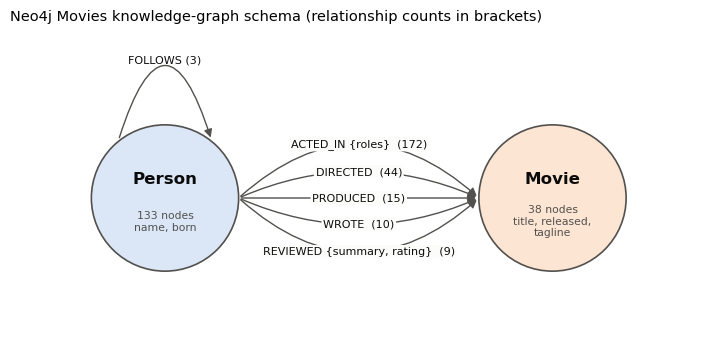

In [26]:
SCHEMA_TEXT = """Node labels and properties:
  (:Movie {title: STRING (unique), released: INTEGER, tagline: STRING})
  (:Person {name: STRING (unique), born: INTEGER})
Relationships:
  (:Person)-[:ACTED_IN {roles: LIST<STRING>}]->(:Movie)
  (:Person)-[:DIRECTED]->(:Movie)
  (:Person)-[:PRODUCED]->(:Movie)
  (:Person)-[:WROTE]->(:Movie)
  (:Person)-[:REVIEWED {summary: STRING, rating: INTEGER}]->(:Movie)
  (:Person)-[:FOLLOWS]->(:Person)"""

def draw_schema(path=None):
    from matplotlib.patches import Circle, FancyArrowPatch
    c = GRAPH.counts()
    fig, ax = plt.subplots(figsize=(9, 4.2)); ax.set_xlim(0, 9); ax.set_ylim(0, 4.2); ax.axis("off")
    P, M = (2.0, 2.0), (7.0, 2.0)
    for (x, y), label, fc, sub in [(P, "Person", "#dbe7f6", f"{c['Person']} nodes\nname, born"),
                                   (M, "Movie", "#fde5d3", f"{c['Movie']} nodes\ntitle, released,\ntagline")]:
        ax.add_patch(Circle((x, y), 0.95, fc=fc, ec="#52514e", lw=1.2))
        ax.text(x, y + 0.25, label, ha="center", va="center", fontsize=12, weight="bold", color="#0b0b0b")
        ax.text(x, y - 0.3, sub, ha="center", va="center", fontsize=7.8, color="#52514e")
    rels = [("ACTED_IN {roles}", 0.45), ("DIRECTED", 0.22), ("PRODUCED", 0.0), ("WROTE", -0.22), ("REVIEWED {summary, rating}", -0.45)]
    for (name, rad) in rels:
        key = name.split()[0]
        ax.add_patch(FancyArrowPatch((P[0] + 0.95, P[1]), (M[0] - 0.95, M[1]), connectionstyle=f"arc3,rad={-rad}",
                                     arrowstyle="-|>", mutation_scale=12, color="#52514e", lw=1))
        ax.text(4.5, 2.0 + rad * 1.55, f"{name}  ({c.get(key, 0)})", ha="center", va="center", fontsize=8,
                color="#0b0b0b", bbox=dict(boxstyle="round,pad=0.15", fc="#fcfcfb", ec="none"))
    ax.add_patch(FancyArrowPatch((P[0] - 0.6, P[1] + 0.75), (P[0] + 0.6, P[1] + 0.75), connectionstyle="arc3,rad=-1.6",
                                 arrowstyle="-|>", mutation_scale=12, color="#52514e", lw=1))
    ax.text(P[0], 3.75, f"FOLLOWS ({c.get('FOLLOWS', 0)})", ha="center", fontsize=8, color="#0b0b0b")
    ax.set_title("Neo4j Movies knowledge-graph schema (relationship counts in brackets)", loc="left", fontsize=10.5)
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig
draw_schema(OUT / "kg_schema.png"); plt.show()

## 3. Cypher query templates

Each template is a **parameterised** Cypher query: values such as `$title` or `$name` are passed as parameters and never pasted into the query string. This prevents Cypher injection and lets Neo4j cache the query plan. Each template has a name, a description used by the router, the parameters it needs and an example question. The templates cover look-ups (details, cast, crew, filmography, roles, reviews), relationships between people (worked together, co-actors, shortest connection), aggregations (busiest actors, top-rated films, directors who acted in their own films), filtering (by year range, by title keyword) and **recommendations** (films that share cast and crew; films of a person's co-actors).

The offline backend implements each template as a Python function returning the same columns. §8.4 checks that both give the same rows.

In [27]:
PEOPLE_RELS = "ACTED_IN|DIRECTED|PRODUCED|WROTE"
TEMPLATES = {
 "movie_details": dict(params=["title"], example="When was The Matrix released?",
   description="Release year, tagline, directors, writers, producers and cast size of a movie",
   cypher="""MATCH (m:Movie {title: $title})
OPTIONAL MATCH (d:Person)-[:DIRECTED]->(m)
OPTIONAL MATCH (w:Person)-[:WROTE]->(m)
OPTIONAL MATCH (p:Person)-[:PRODUCED]->(m)
RETURN m.title AS title, m.released AS released, m.tagline AS tagline,
       collect(DISTINCT d.name) AS directors, collect(DISTINCT w.name) AS writers,
       collect(DISTINCT p.name) AS producers, size([(a:Person)-[:ACTED_IN]->(m) | a]) AS cast_size"""),
 "movie_cast": dict(params=["title"], example="Who acted in The Matrix?",
   description="Actors of a movie with the characters they played",
   cypher="""MATCH (p:Person)-[r:ACTED_IN]->(m:Movie {title: $title})
RETURN p.name AS actor, r.roles AS roles
ORDER BY actor"""),
 "movie_directors": dict(params=["title"], example="Who directed Cloud Atlas?", description="Directors of a movie",
   cypher="""MATCH (p:Person)-[:DIRECTED]->(m:Movie {title: $title})
RETURN p.name AS name ORDER BY name"""),
 "movie_writers": dict(params=["title"], example="Who wrote A Few Good Men?", description="Writers of a movie",
   cypher="""MATCH (p:Person)-[:WROTE]->(m:Movie {title: $title})
RETURN p.name AS name ORDER BY name"""),
 "movie_producers": dict(params=["title"], example="Who produced The Matrix?", description="Producers of a movie",
   cypher="""MATCH (p:Person)-[:PRODUCED]->(m:Movie {title: $title})
RETURN p.name AS name ORDER BY name"""),
 "person_filmography": dict(params=["name"], example="Which movies did Tom Hanks act in?",
   description="Every movie a person acted in, directed, produced or wrote",
   cypher=f"""MATCH (p:Person {{name: $name}})-[r:{PEOPLE_RELS}]->(m:Movie)
RETURN type(r) AS relation, m.title AS title, m.released AS released, r.roles AS roles
ORDER BY released, title, relation"""),
 "person_info": dict(params=["name"], example="When was Keanu Reeves born?",
   description="Birth year and number of acting, directing, writing and producing credits of a person",
   cypher="""MATCH (p:Person {name: $name})
RETURN p.name AS name, p.born AS born,
       size([(p)-[:ACTED_IN]->(m) | m]) AS acted, size([(p)-[:DIRECTED]->(m) | m]) AS directed,
       size([(p)-[:WROTE]->(m) | m]) AS wrote, size([(p)-[:PRODUCED]->(m) | m]) AS produced"""),
 "role_in_movie": dict(params=["name", "title"], example="What role did Hugo Weaving play in The Matrix?",
   description="Characters a person played in a movie",
   cypher="""MATCH (p:Person {name: $name})-[r:ACTED_IN]->(m:Movie {title: $title})
RETURN p.name AS actor, m.title AS title, r.roles AS roles"""),
 "movies_together": dict(params=["name1", "name2"], example="Which movies did Tom Hanks and Meg Ryan both appear in?",
   description="Movies two people both worked on, and in what capacity",
   cypher=f"""MATCH (a:Person {{name: $name1}})-[r1:{PEOPLE_RELS}]->(m:Movie)<-[r2:{PEOPLE_RELS}]-(b:Person {{name: $name2}})
RETURN m.title AS title, m.released AS released,
       collect(DISTINCT type(r1)) AS credits1, collect(DISTINCT type(r2)) AS credits2
ORDER BY released, title"""),
 "coactors": dict(params=["name"], example="Who has Keanu Reeves acted with most often?",
   description="People who acted alongside a person, ranked by number of shared movies",
   cypher="""MATCH (p:Person {name: $name})-[:ACTED_IN]->(m:Movie)<-[:ACTED_IN]-(c:Person)
RETURN c.name AS coactor, count(DISTINCT m) AS shared_movies, collect(DISTINCT m.title) AS movies
ORDER BY shared_movies DESC, coactor LIMIT 10"""),
 "movies_by_year": dict(params=["year_from", "year_to"], example="What movies were released in 1999?",
   description="Movies released in a year or a range of years",
   cypher="""MATCH (m:Movie) WHERE m.released >= $year_from AND m.released <= $year_to
RETURN m.title AS title, m.released AS released ORDER BY released, title"""),
 "search_title": dict(params=["keyword"], example="Which movies have 'Matrix' in the title?",
   description="Movies whose title contains a keyword",
   cypher="""MATCH (m:Movie) WHERE toLower(m.title) CONTAINS toLower($keyword)
RETURN m.title AS title, m.released AS released ORDER BY released, title"""),
 "reviews": dict(params=["title"], example="What did critics say about The Replacements?",
   description="Critics' reviews (summary and 0-100 rating) of a movie",
   cypher="""MATCH (c:Person)-[r:REVIEWED]->(m:Movie {title: $title})
RETURN c.name AS reviewer, r.rating AS rating, r.summary AS summary ORDER BY rating DESC, reviewer"""),
 "top_rated": dict(params=["limit"], example="Which movies have the best reviews?",
   description="Movies ranked by average critic rating",
   cypher="""MATCH (:Person)-[r:REVIEWED]->(m:Movie)
RETURN m.title AS title, avg(r.rating) AS avg_rating, count(r) AS reviews
ORDER BY avg_rating DESC, title LIMIT $limit"""),
 "most_prolific_actors": dict(params=["limit"], example="Who has acted in the most movies?",
   description="Actors ranked by number of acting credits",
   cypher="""MATCH (p:Person)-[:ACTED_IN]->(m:Movie)
RETURN p.name AS actor, count(m) AS movies ORDER BY movies DESC, actor LIMIT $limit"""),
 "director_actors": dict(params=[], example="Which directors acted in their own movies?",
   description="People who directed a movie and also acted in it",
   cypher="""MATCH (p:Person)-[:DIRECTED]->(m:Movie)<-[:ACTED_IN]-(p)
RETURN p.name AS name, collect(m.title) AS movies ORDER BY name"""),
 "shortest_path": dict(params=["name1", "name2"], example="How is Kevin Bacon connected to Meg Ryan?",
   description="Shortest chain of acting/directing credits linking two people ('six degrees')",
   cypher="""MATCH (a:Person {name: $name1}), (b:Person {name: $name2})
MATCH path = shortestPath((a)-[:ACTED_IN|DIRECTED*..10]-(b))
RETURN [n IN nodes(path) | coalesce(n.name, n.title)] AS path, length(path) AS hops"""),
 "recommend_similar_movies": dict(params=["title"], example="Recommend movies similar to The Matrix",
   description="Recommendation: other movies sharing the most cast and crew with a movie",
   cypher=f"""MATCH (m:Movie {{title: $title}})<-[:{PEOPLE_RELS}]-(p:Person)-[:{PEOPLE_RELS}]->(rec:Movie)
WHERE rec <> m
RETURN rec.title AS title, count(DISTINCT p) AS shared_people, collect(DISTINCT p.name) AS via
ORDER BY shared_people DESC, title LIMIT 5"""),
 "recommend_for_person": dict(params=["name"], example="Recommend something for a fan of Tom Hanks",
   description="Recommendation: movies of a person's co-actors that the person has not acted in",
   cypher="""MATCH (p:Person {name: $name})-[:ACTED_IN]->(:Movie)<-[:ACTED_IN]-(c:Person)-[:ACTED_IN]->(rec:Movie)
WHERE NOT EXISTS { (p)-[:ACTED_IN]->(rec) }
RETURN rec.title AS title, count(DISTINCT c) AS coactors, collect(DISTINCT c.name) AS via
ORDER BY coactors DESC, title LIMIT 5"""),
}
for name, t in TEMPLATES.items():
    t["name"] = name

# ---- offline equivalents (same columns, same ordering rules) ------------------------------------
CREDIT = {"ACTED_IN", "DIRECTED", "PRODUCED", "WROTE"}
def _people(g, title, typ):  return sorted(a for t, a, p in g.inc[title] if t == typ)
def _credits(g, name, types=CREDIT):  return [(t, b, p) for t, b, p in g.out[name] if t in types]

def _movie_details(g, title):
    if title not in g.movies: return []
    m = g.movies[title]
    return [{"title": title, "released": m.get("released"), "tagline": m.get("tagline"),
             "directors": _people(g, title, "DIRECTED"), "writers": _people(g, title, "WROTE"),
             "producers": _people(g, title, "PRODUCED"), "cast_size": len(_people(g, title, "ACTED_IN"))}]
def _movie_cast(g, title):
    return sorted(({"actor": a, "roles": p.get("roles")} for t, a, p in g.inc[title] if t == "ACTED_IN"), key=lambda r: r["actor"])
def _crew(typ):
    return lambda g, title: [{"name": n} for n in _people(g, title, typ)]
def _filmography(g, name):
    rows = [{"relation": t, "title": b, "released": g.movies[b].get("released"), "roles": p.get("roles")}
            for t, b, p in _credits(g, name)]
    return sorted(rows, key=lambda r: (r["released"], r["title"], r["relation"]))
def _person_info(g, name):
    if name not in g.people: return []
    cnt = Counter(t for t, b, p in g.out[name])
    return [{"name": name, "born": g.people[name].get("born"), "acted": cnt["ACTED_IN"], "directed": cnt["DIRECTED"],
             "wrote": cnt["WROTE"], "produced": cnt["PRODUCED"]}]
def _role(g, name, title):
    return [{"actor": name, "title": title, "roles": p.get("roles")} for t, b, p in g.out[name] if t == "ACTED_IN" and b == title]
def _together(g, name1, name2):
    c1, c2 = defaultdict(set), defaultdict(set)
    for t, b, p in _credits(g, name1): c1[b].add(t)
    for t, b, p in _credits(g, name2): c2[b].add(t)
    rows = [{"title": m, "released": g.movies[m].get("released"), "credits1": sorted(c1[m]), "credits2": sorted(c2[m])}
            for m in set(c1) & set(c2)]
    return sorted(rows, key=lambda r: (r["released"], r["title"]))
def _coactors(g, name):
    shared = defaultdict(set)
    for t, m, p in g.out[name]:
        if t == "ACTED_IN":
            for t2, c, p2 in g.inc[m]:
                if t2 == "ACTED_IN" and c != name: shared[c].add(m)
    rows = [{"coactor": c, "shared_movies": len(ms), "movies": sorted(ms)} for c, ms in shared.items()]
    return sorted(rows, key=lambda r: (-r["shared_movies"], r["coactor"]))[:10]
def _by_year(g, year_from, year_to):
    rows = [{"title": t, "released": m["released"]} for t, m in g.movies.items()
            if m.get("released") is not None and year_from <= m["released"] <= year_to]
    return sorted(rows, key=lambda r: (r["released"], r["title"]))
def _search(g, keyword):
    return sorted(({"title": t, "released": m.get("released")} for t, m in g.movies.items() if keyword.lower() in t.lower()),
                  key=lambda r: (r["released"], r["title"]))
def _reviews(g, title):
    rows = [{"reviewer": a, "rating": p.get("rating"), "summary": p.get("summary")} for t, a, p in g.inc[title] if t == "REVIEWED"]
    return sorted(rows, key=lambda r: (-r["rating"], r["reviewer"]))
def _top_rated(g, limit):
    agg = defaultdict(list)
    for a, t, b, p in g.rels:
        if t == "REVIEWED": agg[b].append(p["rating"])
    rows = [{"title": m, "avg_rating": sum(v) / len(v), "reviews": len(v)} for m, v in agg.items()]
    return sorted(rows, key=lambda r: (-r["avg_rating"], r["title"]))[:limit]
def _prolific(g, limit):
    c = Counter(a for a, t, b, p in g.rels if t == "ACTED_IN")
    return sorted(({"actor": a, "movies": n} for a, n in c.items()), key=lambda r: (-r["movies"], r["actor"]))[:limit]
def _director_actors(g):
    acted = {(a, b) for a, t, b, p in g.rels if t == "ACTED_IN"}
    res = defaultdict(list)
    for a, t, b, p in g.rels:
        if t == "DIRECTED" and (a, b) in acted: res[a].append(b)
    return [{"name": n, "movies": sorted(ms)} for n, ms in sorted(res.items())]
def _shortest_path(g, name1, name2):
    if name1 not in g.people or name2 not in g.people: return []
    adj = defaultdict(set)
    for a, t, b, p in g.rels:
        if t in ("ACTED_IN", "DIRECTED"): adj[a].add(b); adj[b].add(a)
    prev, q = {name1: None}, deque([name1])
    while q:
        u = q.popleft()
        if u == name2: break
        for v in sorted(adj[u]):
            if v not in prev: prev[v] = u; q.append(v)
    if name2 not in prev or name1 == name2: return []
    path, u = [], name2
    while u is not None: path.append(u); u = prev[u]
    path = path[::-1]
    return [{"path": path, "hops": len(path) - 1}]
def _rec_similar(g, title):
    mine = {a for t, a, p in g.inc[title] if t in CREDIT}
    shared = defaultdict(set)
    for person in mine:
        for t, m, p in _credits(g, person):
            if m != title: shared[m].add(person)
    rows = [{"title": m, "shared_people": len(ps), "via": sorted(ps)} for m, ps in shared.items()]
    return sorted(rows, key=lambda r: (-r["shared_people"], r["title"]))[:5]
def _rec_person(g, name):
    mine = {m for t, m, p in g.out[name] if t == "ACTED_IN"}
    co = {c for m in mine for t, c, p in g.inc[m] if t == "ACTED_IN" and c != name}
    via = defaultdict(set)
    for c in co:
        for t, m, p in g.out[c]:
            if t == "ACTED_IN" and m not in mine: via[m].add(c)
    rows = [{"title": m, "coactors": len(cs), "via": sorted(cs)} for m, cs in via.items()]
    return sorted(rows, key=lambda r: (-r["coactors"], r["title"]))[:5]

OFFLINE_IMPL = {"movie_details": _movie_details, "movie_cast": _movie_cast, "movie_directors": _crew("DIRECTED"),
                "movie_writers": _crew("WROTE"), "movie_producers": _crew("PRODUCED"), "person_filmography": _filmography,
                "person_info": _person_info, "role_in_movie": _role, "movies_together": _together, "coactors": _coactors,
                "movies_by_year": _by_year, "search_title": _search, "reviews": _reviews, "top_rated": _top_rated,
                "most_prolific_actors": _prolific, "director_actors": _director_actors, "shortest_path": _shortest_path,
                "recommend_similar_movies": _rec_similar, "recommend_for_person": _rec_person}
assert set(OFFLINE_IMPL) == set(TEMPLATES)

with open(OUT / "cypher_templates.cypher", "w") as f:
    for name, t in TEMPLATES.items():
        f.write(f"// {name}({', '.join(t['params'])}): {t['description']}\n// e.g. \"{t['example']}\"\n{t['cypher']};\n\n")
print(len(TEMPLATES), "templates written to", OUT / "cypher_templates.cypher")
pd.DataFrame([{"template": n, "parameters": ", ".join(t["params"]) or "-", "example question": t["example"],
               "description": t["description"]} for n, t in TEMPLATES.items()])

19 templates written to outputs\cypher_templates.cypher


,template,parameters,example question,description
0,movie_details,title,When was The Matrix released?,"Release year, tagline, directors, writers, producers and cast size of a movie"
1,movie_cast,title,Who acted in The Matrix?,Actors of a movie with the characters they played
2,movie_directors,title,Who directed Cloud Atlas?,Directors of a movie
3,movie_writers,title,Who wrote A Few Good Men?,Writers of a movie
4,movie_producers,title,Who produced The Matrix?,Producers of a movie
5,person_filmography,name,Which movies did Tom Hanks act in?,"Every movie a person acted in, directed, produced or wrote"
6,person_info,name,When was Keanu Reeves born?,"Birth year and number of acting, directing, writing and producing credits of a person"
7,role_in_movie,"name, title",What role did Hugo Weaving play in The Matrix?,Characters a person played in a movie
8,movies_together,"name1, name2",Which movies did Tom Hanks and Meg Ryan both appear in?,"Movies two people both worked on, and in what capacity"
9,coactors,name,Who has Keanu Reeves acted with most often?,"People who acted alongside a person, ranked by number of shared movies"


In [28]:
print(TEMPLATES["recommend_similar_movies"]["cypher"], "\n")
pd.DataFrame(GRAPH.run_template("recommend_similar_movies", {"title": "The Matrix"}))

MATCH (m:Movie {title: $title})<-[:ACTED_IN|DIRECTED|PRODUCED|WROTE]-(p:Person)-[:ACTED_IN|DIRECTED|PRODUCED|WROTE]->(rec:Movie)
WHERE rec <> m
RETURN rec.title AS title, count(DISTINCT p) AS shared_people, collect(DISTINCT p.name) AS via
ORDER BY shared_people DESC, title LIMIT 5 



,title,shared_people,via
0,The Matrix Reloaded,7,"[Keanu Reeves, Carrie-Anne Moss, Laurence Fishburne, Hugo Weaving, Lilly Wachowski, Lana Wachows..."
1,The Matrix Revolutions,7,"[Keanu Reeves, Carrie-Anne Moss, Laurence Fishburne, Hugo Weaving, Lilly Wachowski, Lana Wachows..."
2,V for Vendetta,4,"[Hugo Weaving, Lilly Wachowski, Lana Wachowski, Joel Silver]"
3,Cloud Atlas,3,"[Hugo Weaving, Lilly Wachowski, Lana Wachowski]"
4,Ninja Assassin,3,"[Lilly Wachowski, Lana Wachowski, Joel Silver]"


## 4. From question to Cypher, step 1: entity linking and template routing

**Entity linking** grounds the question in the graph before any query runs. The gazetteer is the list of every `Movie.title` and `Person.name` fetched **from the database itself**, so it updates automatically if the graph changes. Three passes, each only over text not yet matched:
1. **Exact match** of a full title or name, case-insensitive, longest first (*"sleepless in seattle"* → `Sleepless in Seattle`).
2. **Short forms**: a title without its leading *The* or *A* (*"Matrix Reloaded"*), or a capitalised first or last name that belongs to exactly one person (*"Keanu"*, *"Hanks"*).
3. **Fuzzy match** for typos with `difflib` (*"Tom Hanx"* → `Tom Hanks`, *"Sleepless in Seatle"*), with a similarity cut-off of 0.82.

Years and ranges (*1999*, *between 1990 and 1995*, *the 1990s*, *before 1990*) are extracted with regular expressions. Pronouns (*it*, *that movie*, *he*, *she*) resolve to the last movie or person mentioned in the conversation.

**Routing.** Ordered rules over the linked entity types and the question's wording choose a template, for example *movie + "who directed"* → `movie_directors`, *two people + "connected"* → `shortest_path`, *movie + "similar / recommend"* → `recommend_similar_movies`. Questions about attributes the graph does not store (genre, box office, awards, salary …) are refused with an explanation. If no rule applies, the question goes to **LLM text-to-Cypher** (§5), or is refused politely when no LLM is configured.

In [29]:
def _norm(s):
    return re.sub(r"\s+", " ", s.replace("’", "'").lower()).strip()

TITLES, NAMES = GRAPH.titles(), GRAPH.names()
ENTITIES = [(t, "Movie") for t in TITLES] + [(n, "Person") for n in NAMES]
SHORT_FORMS = {}
for t in TITLES:
    core = re.sub(r"^(the|a) ", "", t, flags=re.I)
    if core != t and sum(_norm(core) in _norm(x) for x in TITLES) == 1:
        SHORT_FORMS[_norm(core)] = (t, "Movie")
for part in (0, -1):
    tokens = Counter(n.split()[part] for n in NAMES)
    for n in NAMES:
        tok = n.split()[part]
        if tokens[tok] == 1 and len(tok) > 3 and not any(_norm(tok) in _norm(t) for t in TITLES):
            SHORT_FORMS.setdefault(_norm(tok), (n, "Person"))

def link_entities(question, fuzzy_cutoff=0.82):
    q = _norm(question)
    taken, found = [False] * len(q), []
    def claim(a, b, ent, how):
        if not any(taken[a:b]):
            taken[a:b] = [True] * (b - a)
            found.append({"text": question[a:b] if len(question) == len(q) else q[a:b], "entity": ent[0], "type": ent[1], "match": how, "pos": a})
    for ent in sorted(ENTITIES, key=lambda e: -len(e[0])):                       # 1. exact
        for m in re.finditer(r"(?<!\w)" + re.escape(_norm(ent[0])) + r"(?!\w)", q):
            claim(m.start(), m.end(), ent, "exact")
    for form, ent in sorted(SHORT_FORMS.items(), key=lambda kv: -len(kv[0])):    # 2. short forms
        for m in re.finditer(r"(?<!\w)" + re.escape(form) + r"(?!\w)", q):
            original = question[m.start():m.end()] if len(question) == len(q) else form
            if ent[1] == "Movie" or original[:1].isupper():
                claim(m.start(), m.end(), ent, "short form")
    words = [(m.start(), m.end()) for m in re.finditer(r"[\w'/-]+", q)]          # 3. fuzzy n-grams
    cands = []
    for i in range(len(words)):
        for j in range(i, min(i + 6, len(words))):
            a, b = words[i][0], words[j][1]
            if any(taken[a:b]) or b - a < 5:
                continue
            span = q[a:b]
            for ent in ENTITIES:
                target = _norm(ent[0])
                if abs(len(target) - len(span)) > 0.3 * len(target):
                    continue
                r = difflib.SequenceMatcher(None, span, target).ratio()
                if r >= fuzzy_cutoff:
                    cands.append((r, a, b, ent))
    for r, a, b, ent in sorted(cands, key=lambda c: (-c[0], c[1])):
        if not any(e["entity"] == ent[0] for e in found):
            claim(a, b, ent, f"fuzzy {r:.2f}")
    return sorted(found, key=lambda e: e["pos"])

def extract_years(question):
    q = question.lower()
    if m := re.search(r"\b(?:the )?(19|20)(\d)0s\b", q):
        y = int(m.group(1) + m.group(2) + "0"); return (y, y + 9)
    if m := re.search(r"between (\d{4}) and (\d{4})", q):
        return (int(m.group(1)), int(m.group(2)))
    if m := re.search(r"\b(before|after|since) (\d{4})\b", q):
        y = int(m.group(2)); return (1800, y - 1) if m.group(1) == "before" else (y + (m.group(1) == "after"), 2100)
    if m := re.search(r"\b(19\d{2}|20\d{2})\b", q):
        y = int(m.group(1)); return (y, y)
    return None

UNSUPPORTED = r"\b(genre|comed(y|ies)|horror|thriller|box office|gross|budget|award|oscar|salary|net worth|height|wife|husband|married|spouse|nationality|country|language|runtime|how long is the movie|imdb|streaming|netflix)\b"

def route(question, ents, memory):
    """Rule-based router -> (template name, params) | ('UNSUPPORTED', reason) | (None, None)."""
    q = question.lower()
    movies = [e["entity"] for e in ents if e["type"] == "Movie"]
    people = [e["entity"] for e in ents if e["type"] == "Person"]
    if not movies and memory.get("movie") and re.search(r"\b(it|that movie|this movie|the movie|that film|this film|the film)\b", q):
        movies = [memory["movie"]]
    if not people and memory.get("person") and re.search(r"\b(he|she|him|her|his|they|them)\b", q):
        people = [memory["person"]]
    if re.search(UNSUPPORTED, q):
        return "UNSUPPORTED", "The Movies graph only stores titles, release years, taglines, people, their birth years, credits, roles and critic reviews."
    if re.search(r"recommend|suggest|similar|what else|should i (watch|see)|fans? of|if i (liked|enjoyed|loved?)", q):
        if movies:  return "recommend_similar_movies", {"title": movies[0]}
        if people:  return "recommend_for_person", {"name": people[0]}
    if len(people) >= 2:
        if re.search(r"connect|path|link|degree|related|separation|chain", q):
            return "shortest_path", {"name1": people[0], "name2": people[1]}
        return "movies_together", {"name1": people[0], "name2": people[1]}
    if people and movies:
        return "role_in_movie", {"name": people[0], "title": movies[0]}
    if movies:
        t = {"title": movies[0]}
        if re.search(r"review|critic|rating|rated|say about|reception", q): return "reviews", t
        if re.search(r"direct", q):                                       return "movie_directors", t
        if re.search(r"\bwr[io]te|writer|written|screenplay|script", q):  return "movie_writers", t
        if re.search(r"produc", q):                                       return "movie_producers", t
        if re.search(r"\bcast\b|actor|actress|starr?|acted|act in|appear|played|plays|characters?|roles?|who (was|is|were) in", q):
            return "movie_cast", t
        return "movie_details", t
    if people:
        n = {"name": people[0]}
        if re.search(r"born|how old|\bage\b|birth", q):                   return "person_info", n
        if re.search(r"acted with|co-?star|worked with|work with|alongside|most often|together with", q):
            return "coactors", n
        return "person_filmography", n
    if re.search(r"(most|more) (movies|films)|prolific|busiest|appears? in the most", q):
        return "most_prolific_actors", {"limit": 5}
    if re.search(r"direct\w*.*\b(act|star)|(act|star)\w* in their own", q):
        return "director_actors", {}
    if re.search(r"\b(best|top|highest)\b.*\b(rated|reviews?|rating)|best reviewed|highest rated", q):
        return "top_rated", {"limit": 5}
    if (kw := re.search(r"['\"]([^'\"]{3,})['\"]", question)) and re.search(r"title|called|named", q):
        return "search_title", {"keyword": kw.group(1)}
    if (yrs := extract_years(question)) and re.search(r"movie|film|released|came out|come out", q):
        return "movies_by_year", {"year_from": yrs[0], "year_to": yrs[1]}
    return None, None

for q in ["Who directed the Matrix Reloaded?", "What movies has Tom Hanx been in?", "How is Kevin Bacon connected to Meg Ryan?",
          "Movies from the 1990s with Keanu?", "Which comedies did Meg Ryan make?"]:
    e = link_entities(q)
    print(f"{q!r:48} -> {[(x['entity'], x['match']) for x in e]} -> {route(q, e, {})}")

'Who directed the Matrix Reloaded?'              -> [('The Matrix Reloaded', 'exact')] -> ('movie_directors', {'title': 'The Matrix Reloaded'})
'What movies has Tom Hanx been in?'              -> [('Tom Hanks', 'fuzzy 0.82')] -> ('person_filmography', {'name': 'Tom Hanks'})
'How is Kevin Bacon connected to Meg Ryan?'      -> [('Kevin Bacon', 'exact'), ('Meg Ryan', 'exact')] -> ('shortest_path', {'name1': 'Kevin Bacon', 'name2': 'Meg Ryan'})
'Movies from the 1990s with Keanu?'              -> [('Keanu Reeves', 'short form')] -> ('person_filmography', {'name': 'Keanu Reeves'})
'Which comedies did Meg Ryan make?'              -> [('Meg Ryan', 'exact')] -> ('UNSUPPORTED', 'The Movies graph only stores titles, release years, taglines, people, their birth years, credits, roles and critic reviews.')


## 5. From question to Cypher, step 2: LLM text-to-Cypher for questions no template covers

When no template fits (for example *"Which Tom Hanks movies came out before 1995?"*), the LLM writes the Cypher. The prompt contains the **graph schema**, rules (read-only, only the listed labels and relationship types, parameters written as literals, always a `LIMIT`) and **few-shot examples** built from the templates. The generated query passes through a **safety guard** before it runs: it must start with a read clause; write and administrative clauses (`CREATE`, `MERGE`, `DELETE`, `SET`, `REMOVE`, `DROP`, `LOAD CSV`, `CALL dbms/apoc`, `FOREACH`) are rejected; a `LIMIT` is added if missing; and it runs in a **read transaction**, so even a query that slips past the guard cannot change the database. If Neo4j reports an error, the error is sent back to the LLM once for a corrected query.

In [30]:
def call_llm(system, user, temperature=0.0, max_tokens=2000):
    """One chat completion from the configured provider (OpenAI-compatible API, or Anthropic's Messages API)."""
    base = LLM_PRESETS[LLM_PROVIDER][0]
    if LLM_PROVIDER == "anthropic":
        r = requests.post(f"{base}/messages", timeout=90,
                          headers={"x-api-key": LLM_API_KEY, "anthropic-version": "2023-06-01", "content-type": "application/json"},
                          json={"model": LLM_MODEL, "max_tokens": max_tokens, "temperature": temperature, "system": system,
                                "messages": [{"role": "user", "content": user}]})
        if not r.ok:
            raise RuntimeError(f"LLM API error {r.status_code}: {r.text[:300]}")
        return "".join(b.get("text", "") for b in r.json()["content"]).strip()
    headers = {"Content-Type": "application/json"}
    if LLM_API_KEY:
        headers["Authorization"] = f"Bearer {LLM_API_KEY}"
    body = {"model": LLM_MODEL, "temperature": temperature, "max_tokens": max_tokens,
            "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}]}
    if LLM_PROVIDER == "groq" and "gpt-oss" in LLM_MODEL:     # reasoning model: keep thinking short, return only the answer
        body.update({"reasoning_effort": "low", "include_reasoning": False})
    for attempt in range(3):                                   # simple retry on rate limits (free tiers)
        r = requests.post(f"{base}/chat/completions", timeout=90, headers=headers, json=body)
        if r.status_code != 429:
            break
        time.sleep(float(r.headers.get("retry-after", 5)))
    if not r.ok:
        raise RuntimeError(f"LLM API error {r.status_code}: {r.text[:300]}")
    return (r.json()["choices"][0]["message"].get("content") or "").strip()

FEW_SHOT = [
    ("Who directed Cloud Atlas?", "MATCH (p:Person)-[:DIRECTED]->(m:Movie {title: 'Cloud Atlas'}) RETURN p.name AS director LIMIT 25"),
    ("Which movies did Tom Hanks and Meg Ryan both act in?",
     "MATCH (a:Person {name: 'Tom Hanks'})-[:ACTED_IN]->(m:Movie)<-[:ACTED_IN]-(b:Person {name: 'Meg Ryan'}) RETURN m.title AS title, m.released AS released ORDER BY released LIMIT 25"),
    ("Who has acted in the most movies?",
     "MATCH (p:Person)-[:ACTED_IN]->(m:Movie) RETURN p.name AS actor, count(m) AS movies ORDER BY movies DESC LIMIT 5"),
    ("Which movies released before 1990 did Jack Nicholson act in?",
     "MATCH (p:Person {name: 'Jack Nicholson'})-[:ACTED_IN]->(m:Movie) WHERE m.released < 1990 RETURN m.title AS title, m.released AS released ORDER BY released LIMIT 25"),
]
CYPHER_SYSTEM = f"""You translate questions about a movie database into a single read-only Neo4j Cypher query.
{SCHEMA_TEXT}
Rules: use only these labels, relationship types and properties; never write data (no CREATE, MERGE, DELETE, SET, REMOVE, DROP, LOAD CSV, CALL);
write literal values directly in the query; give every returned column an alias with AS; end with LIMIT 25 or smaller;
reply with the Cypher query only, without explanations or code fences."""

FORBIDDEN = re.compile(r"\b(CREATE|MERGE|DELETE|DETACH|SET|REMOVE|DROP|FOREACH|LOAD\s+CSV|CALL\s+(dbms|apoc|db\.(create|drop)))\b", re.I)
def guard_cypher(cypher):
    fenced = re.search(r"```(?:cypher)?\s*(.*?)```", cypher, re.S | re.I)      # keep only the query if the model added text
    cypher = (fenced.group(1) if fenced else cypher).strip()
    start = re.search(r"^\s*(MATCH|OPTIONAL\s+MATCH|WITH|UNWIND|RETURN)\b", cypher, re.I | re.M)
    cypher = (cypher[start.start():] if start else cypher).strip().rstrip(";")
    if not re.match(r"^(MATCH|OPTIONAL\s+MATCH|WITH|UNWIND|RETURN)\b", cypher, re.I):
        raise ValueError("query must start with a read clause")
    if FORBIDDEN.search(cypher):
        raise ValueError("write or admin clause rejected: " + FORBIDDEN.search(cypher).group(0))
    if not re.search(r"\bLIMIT\s+\d+\s*$", cypher, re.I):
        cypher += " LIMIT 25"
    return cypher

def text_to_cypher(question, entities):
    hints = "; ".join(f"{e['type']} '{e['entity']}'" for e in entities) or "none"
    shots = "\n\n".join(f"Question: {q}\nCypher: {c}" for q, c in FEW_SHOT)
    user = f"{shots}\n\nEntities found in the question (use these exact spellings): {hints}\nQuestion: {question}\nCypher:"
    cypher = guard_cypher(call_llm(CYPHER_SYSTEM, user))
    try:
        return cypher, GRAPH.run(cypher)
    except Exception as err:           # one repair round with the database's error message
        fixed = guard_cypher(call_llm(CYPHER_SYSTEM, f"{user} {cypher}\n\nThat query failed with: {err}\nWrite a corrected query.\nCypher:"))
        return fixed, GRAPH.run(fixed)

for bad in ["MATCH (n) DETACH DELETE n", "CREATE (:Movie {title:'x'})", "CALL dbms.components()",
            "MATCH (m:Movie) RETURN m.title AS title"]:
    try:
        print(f"{bad!r:45} -> allowed: {guard_cypher(bad)}")
    except ValueError as e:
        print(f"{bad!r:45} -> rejected ({e})")

'MATCH (n) DETACH DELETE n'                   -> rejected (write or admin clause rejected: DETACH)
"CREATE (:Movie {title:'x'})"                 -> rejected (query must start with a read clause)
'CALL dbms.components()'                      -> rejected (query must start with a read clause)
'MATCH (m:Movie) RETURN m.title AS title'     -> allowed: MATCH (m:Movie) RETURN m.title AS title LIMIT 25


## 6. Grounded answer generation

The retrieved rows are serialised as compact JSON **facts** and placed in the LLM prompt together with the question. The system prompt tells the model to use **only** those facts, to copy names and titles exactly, to say so when the facts do not contain the answer, and to explain recommendations through the people that connect the films.

A **groundedness check** runs after generation: every movie title or person name from the graph that appears in the answer must also appear in the retrieved facts (or in the question). Any other title or name is flagged as unsupported, which catches the most visible kind of hallucination.

Without an LLM, a deterministic **template writer** turns the same facts into a sentence, so the rest of the pipeline can still be demonstrated and evaluated.

In [31]:
ANSWER_SYSTEM = """You are MovieGraph Assistant. Answer the user's question using ONLY the facts that were retrieved from a Neo4j movie knowledge graph.
Rules:
- Do not use outside knowledge. If the facts are empty or do not contain the answer, say that the movie database does not contain that information.
- Write movie titles and person names exactly as they appear in the facts.
- Be concise: one to four sentences, or a short list.
- For recommendations, give the titles and say briefly why, using the people listed in 'via'."""

def facts_json(rows, limit=40):
    return "\n".join(json.dumps(r, ensure_ascii=False, default=str) for r in rows[:limit]) or "(no results)"

def _ls(xs):
    xs = list(xs)
    return "none" if not xs else xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " and " + xs[-1]

def template_writer(name, params, rows):
    """Deterministic fallback answer (no LLM)."""
    if not rows:
        return "The movie database does not contain an answer to that question."
    r0 = rows[0]
    if name == "movie_details":
        crew = [f"{label} by {_ls(r0[k])}" for k, label in [("directors", "directed"), ("writers", "written"), ("producers", "produced")] if r0[k]]
        return (f"{r0['title']} was released in {r0['released']}" + (f' (tagline: "{r0["tagline"]}")' if r0.get("tagline") else "")
                + ". " + (("; ".join(crew))[:1].upper() + ("; ".join(crew))[1:] + "; " if crew else "") + f"{r0['cast_size']} actors are listed in the cast.")
    if name == "movie_cast":
        return f"The cast of {params['title']}: " + "; ".join(f"{r['actor']} ({', '.join(r['roles'] or [])})" for r in rows) + "."
    if name in ("movie_directors", "movie_writers", "movie_producers"):
        verb = {"movie_directors": "directed", "movie_writers": "written", "movie_producers": "produced"}[name]
        return f"{params['title']} was {verb} by {_ls(r['name'] for r in rows)}."
    if name == "person_filmography":
        groups = defaultdict(list)
        for r in rows:
            groups[r["relation"]].append(f"{r['title']} ({r['released']})")
        label = {"ACTED_IN": "acted in", "DIRECTED": "directed", "PRODUCED": "produced", "WROTE": "wrote"}
        return f"{params['name']} " + "; ".join(f"{label[k]} {_ls(v)}" for k, v in groups.items()) + "."
    if name == "person_info":
        return (f"{r0['name']} was born in {r0['born']}. In the graph: {r0['acted']} acting, {r0['directed']} directing, "
                f"{r0['wrote']} writing and {r0['produced']} producing credits.") if r0["born"] else f"The graph has no birth year for {r0['name']}."
    if name == "role_in_movie":
        return f"In {r0['title']}, {r0['actor']} played {_ls(r0['roles'] or ['an uncredited role'])}."
    if name == "movies_together":
        return f"{params['name1']} and {params['name2']} both worked on {_ls(r['title'] + ' (' + str(r['released']) + ')' for r in rows)}."
    if name == "coactors":
        return f"{params['name']} most often acted with " + "; ".join(f"{r['coactor']} ({r['shared_movies']} films)" for r in rows[:5]) + "."
    if name in ("movies_by_year", "search_title"):
        return f"{len(rows)} movies: " + "; ".join(f"{r['title']} ({r['released']})" for r in rows) + "."
    if name == "reviews":
        return f"Reviews of {params['title']}: " + "; ".join(f"{r['reviewer']} rated it {r['rating']}/100 — \"{r['summary']}\"" for r in rows) + "."
    if name == "top_rated":
        return "Best-reviewed movies: " + "; ".join(f"{r['title']} (average {r['avg_rating']:.0f}/100 from {r['reviews']} review{'s' * (r['reviews'] > 1)})" for r in rows) + "."
    if name == "most_prolific_actors":
        return "Most acting credits: " + "; ".join(f"{r['actor']} ({r['movies']})" for r in rows) + "."
    if name == "director_actors":
        return "Directors who acted in their own films: " + "; ".join(f"{r['name']} ({_ls(r['movies'])})" for r in rows) + "."
    if name == "shortest_path":
        return (f"{params['name1']} and {params['name2']} are {r0['hops'] // 2} degrees apart ({r0['hops']} hops): "
                + " → ".join(r0["path"]) + ".")
    if name == "recommend_similar_movies":
        return f"If you liked {params['title']}, try: " + "; ".join(f"{r['title']} (shares {_ls(r['via'][:3])})" for r in rows[:3]) + "."
    if name == "recommend_for_person":
        return f"For fans of {params['name']}: " + "; ".join(f"{r['title']} (with co-stars {_ls(r['via'][:3])})" for r in rows[:3]) + "."
    return facts_json(rows, 5)

def unsupported_entities(answer, question, facts, params=None):
    """Graph entities named in the answer that are neither in the retrieved facts, the question, nor the
    resolved query parameters (e.g. the movie a pronoun referred to, or the corrected spelling of a typo)."""
    hay = _norm(facts + " " + json.dumps(params or {}, ensure_ascii=False))
    q = _norm(question)
    return [e for e, _ in ENTITIES if re.search(r"(?<!\w)" + re.escape(_norm(e)) + r"(?!\w)", _norm(answer))
            and _norm(e) not in hay and _norm(e) not in q]

## 7. The RAG application: pipeline, demo conversations and chat loop

`ask()` runs the whole pipeline and returns every intermediate result: the linked entities, the chosen template or generated Cypher, the retrieved rows, the facts given to the generator, the answer and the groundedness check. A small conversation memory keeps the last movie and person, so follow-up questions such as *"When was it released?"* work.

In [32]:
def retrieve(template, params):
    return GRAPH.run_template(template, params)

def ask(question, memory=None):
    memory = memory if memory is not None else {}
    t0 = time.time()
    ents = link_entities(question)
    template, params = route(question, ents, memory)
    out = {"question": question, "entities": [(e["entity"], e["type"], e["match"]) for e in ents],
           "template": template, "params": params, "cypher": None, "rows": [], "answer": None,
           "generator": "LLM" if USE_LLM else "template writer", "unsupported": []}
    if template == "UNSUPPORTED":
        out["answer"] = "Sorry, the movie database does not store that. " + params
        out["template"], out["params"] = "unsupported", None
    elif template is None:
        if USE_LLM:
            try:
                out["cypher"], out["rows"] = text_to_cypher(question, ents)
                out["template"] = "llm_text_to_cypher"
            except Exception as err:
                out["answer"] = f"Sorry, I could not answer that with a generated Cypher query ({err})."
        else:
            out["answer"] = ("Sorry, I couldn't find a movie or person from the database in that question, or it needs a query "
                             "outside my templates (LLM text-to-Cypher is off because no LLM is configured).")
    else:
        out["cypher"] = TEMPLATES[template]["cypher"]
        out["rows"] = retrieve(template, params)
    if out["answer"] is None:
        facts = facts_json(out["rows"])
        out["facts"] = facts
        if USE_LLM:
            desc = TEMPLATES[template]["description"] if template in TEMPLATES else "LLM-generated Cypher"
            try:
                out["answer"] = call_llm(ANSWER_SYSTEM, f"Question: {question}\n\nFacts retrieved from the graph ({desc}):\n{facts}\n\nAnswer:")
            except Exception as err:
                out["answer"] = template_writer(template, params, out["rows"]) if template in TEMPLATES else facts
                out["generator"] = f"template writer (LLM call failed: {err.__class__.__name__})"
        else:
            out["answer"] = template_writer(template, params, out["rows"])
        out["unsupported"] = unsupported_entities(out["answer"], question, facts, params if isinstance(params, dict) else None)
    for e in ents:                                   # conversation memory for follow-ups
        memory["movie" if e["type"] == "Movie" else "person"] = e["entity"]
    out["seconds"] = round(time.time() - t0, 3)
    return out

def show(res, verbose=True):
    print(f"USER: {res['question']}")
    if verbose:
        print(f"  entities : {res['entities'] or '-'}")
        print(f"  route    : {res['template']} {res['params'] or ''}")
        print(f"  retrieved: {len(res['rows'])} row(s); generator: {res['generator']}; unsupported entities: {res['unsupported'] or 'none'}")
    print(f"BOT : {res['answer']}\n")

memory = {}
for q in ["Who acted in The Matrix?", "Who directed it?", "When was it released?", "What role did Hugo Weaving play in it?",
          "Recommend movies similar to The Matrix", "How is Kevin Bacon connected to Meg Ryan?"]:
    show(ask(q, memory))

USER: Who acted in The Matrix?
  entities : [('The Matrix', 'Movie', 'exact')]
  route    : movie_cast {'title': 'The Matrix'}
  retrieved: 5 row(s); generator: LLM; unsupported entities: none
BOT : Carrie‑Anne Moss (Trinity)  
Emil Eifrem (Emil)  
Hugo Weaving (Agent Smith)  
Keanu Reeves (Neo)  
Laurence Fishburne (Morpheus)

USER: Who directed it?
  entities : -
  route    : movie_directors {'title': 'The Matrix'}
  retrieved: 2 row(s); generator: LLM; unsupported entities: none
BOT : It was directed by Lana Wachowski and Lilly Wachowski.

USER: When was it released?
  entities : -
  route    : movie_details {'title': 'The Matrix'}
  retrieved: 1 row(s); generator: LLM; unsupported entities: none
BOT : The movie **The Matrix** was released in **1999**.

USER: What role did Hugo Weaving play in it?
  entities : [('Hugo Weaving', 'Person', 'exact')]
  route    : role_in_movie {'name': 'Hugo Weaving', 'title': 'The Matrix'}
  retrieved: 1 row(s); generator: LLM; unsupported entities: n

In [33]:
memory = {}
for q in ["What movies has Kenau Reeves been in?", "Which movies did Tom Hanks and Meg Ryan both appear in?",
          "Recommend something for a fan of Keanu Reeves", "What did critics say about Jerry Maguire?",
          "Which comedies did Meg Ryan make?", "Who directed Inception?"]:
    show(ask(q, memory))

USER: What movies has Kenau Reeves been in?
  entities : [('Keanu Reeves', 'Person', 'short form')]
  route    : person_filmography {'name': 'Keanu Reeves'}
  retrieved: 7 row(s); generator: LLM; unsupported entities: none
BOT : The movie database does not contain information about “Kenau Reeves.”

USER: Which movies did Tom Hanks and Meg Ryan both appear in?
  entities : [('Tom Hanks', 'Person', 'exact'), ('Meg Ryan', 'Person', 'exact')]
  route    : movies_together {'name1': 'Tom Hanks', 'name2': 'Meg Ryan'}
  retrieved: 3 row(s); generator: LLM; unsupported entities: none
BOT : Tom Hanks and Meg Ryan both appeared in:

- **Joe Versus the Volcano** (1990) – both acted in it.  
- **Sleepless in Seattle** (1993) – both acted in it.  
- **You've Got Mail** (1998) – both acted in it.

USER: Recommend something for a fan of Keanu Reeves
  entities : [('Keanu Reeves', 'Person', 'exact')]
  route    : recommend_for_person {'name': 'Keanu Reeves'}
  retrieved: 5 row(s); generator: LLM; unsup

In [34]:
print("Cypher sent to the database for the recommendation question:\n")
r = ask("If I liked Cloud Atlas, what else should I watch?")
print(r["cypher"], "\nparameters:", r["params"], "\n\nretrieved facts given to the generator:\n" + r["facts"])

Cypher sent to the database for the recommendation question:

MATCH (m:Movie {title: $title})<-[:ACTED_IN|DIRECTED|PRODUCED|WROTE]-(p:Person)-[:ACTED_IN|DIRECTED|PRODUCED|WROTE]->(rec:Movie)
WHERE rec <> m
RETURN rec.title AS title, count(DISTINCT p) AS shared_people, collect(DISTINCT p.name) AS via
ORDER BY shared_people DESC, title LIMIT 5 
parameters: {'title': 'Cloud Atlas'} 

retrieved facts given to the generator:
{"title": "The Matrix", "shared_people": 3, "via": ["Hugo Weaving", "Lilly Wachowski", "Lana Wachowski"]}
{"title": "The Matrix Reloaded", "shared_people": 3, "via": ["Hugo Weaving", "Lilly Wachowski", "Lana Wachowski"]}
{"title": "The Matrix Revolutions", "shared_people": 3, "via": ["Hugo Weaving", "Lilly Wachowski", "Lana Wachowski"]}
{"title": "V for Vendetta", "shared_people": 3, "via": ["Hugo Weaving", "Lilly Wachowski", "Lana Wachowski"]}
{"title": "Ninja Assassin", "shared_people": 2, "via": ["Lilly Wachowski", "Lana Wachowski"]}


In [35]:
def chat():
    """Command-line RAG chat. Type 'quit' to stop."""
    mem = {}
    print("MovieGraph Assistant — ask about movies, actors, directors or recommendations. (" + MODE + ")")
    while True:
        q = input("You: ").strip()
        if q.lower() in {"quit", "exit"}:
            break
        res = ask(q, mem)
        print("Bot:", res["answer"])
        if res["cypher"]:
            print("     [", res["template"], "|", len(res["rows"]), "rows ]")

RUN_INTERACTIVE = False   # set to True to chat with the assistant in this notebook
if RUN_INTERACTIVE:
    chat()

## 8. Evaluation

**Question sets.** The sets were written before the system was built, and their gold answers were derived independently from the raw dataset script. As in the earlier labs there is a **development** set (used while writing the linking and routing rules) and a paraphrased **held-out test** set with typos (*Sleepless in Seatle*), synonyms (*starred*, *come out*, *characters*) and questions the graph cannot answer. A third **harder set** needs filtering or counting that no template does directly, which is where an LLM can add value over the template writer.

**Measures for each question:**
* **Entity linking:** were all gold entities found?
* **Routing:** was the expected template chosen?
* **Context recall:** the share of gold answer items present in the retrieved facts (did retrieval bring back the evidence?).
* **Answer correctness:** depends on the question. Either all gold items appear in the answer; or, for recommendations, the answer names a top-ranked candidate (ties are counted as correct); or the shortest path has the right length and every step is a real edge; or, for questions the graph cannot answer, the answer is a refusal; or, for the harder set, it names exactly the gold titles and no others.
* **Groundedness:** titles or names in the answer that are not supported by the retrieved facts.

In [36]:
EVAL_DEV = [
 ("Who acted in The Matrix?", "movie_cast", ["The Matrix"], {"all": ["Carrie-Anne Moss", "Emil Eifrem", "Hugo Weaving", "Keanu Reeves", "Laurence Fishburne"]}),
 ("Who directed Cloud Atlas?", "movie_directors", ["Cloud Atlas"], {"all": ["Tom Tykwer", "Lilly Wachowski", "Lana Wachowski"]}),
 ("When was Jerry Maguire released?", "movie_details", ["Jerry Maguire"], {"all": ["2000"]}),
 ("Which movies did Tom Hanks act in?", "person_filmography", ["Tom Hanks"], {"all": ["A League of Their Own", "Apollo 13", "Cast Away", "Charlie Wilson's War", "Cloud Atlas", "Joe Versus the Volcano", "Sleepless in Seattle", "That Thing You Do", "The Da Vinci Code", "The Green Mile", "The Polar Express", "You've Got Mail"]}),
 ("In which movies did Tom Hanks and Meg Ryan both appear?", "movies_together", ["Tom Hanks", "Meg Ryan"], {"all": ["Joe Versus the Volcano", "Sleepless in Seattle", "You've Got Mail"]}),
 ("What movies were released in 1999?", "movies_by_year", [], {"all": ["Bicentennial Man", "Snow Falling on Cedars", "The Green Mile", "The Matrix"]}),
 ("When was Keanu Reeves born?", "person_info", ["Keanu Reeves"], {"all": ["1964"]}),
 ("Recommend movies similar to The Matrix", "recommend_similar_movies", ["The Matrix"], {"any": ["The Matrix Reloaded", "The Matrix Revolutions"]}),
 ("What did critics say about The Replacements?", "reviews", ["The Replacements"], {"all": ["Silly, but fun", "The coolest football movie ever", "Pretty funny at times"]}),
 ("Who has acted in the most movies?", "most_prolific_actors", [], {"all": ["Tom Hanks"]}),
 ("How is Kevin Bacon connected to Meg Ryan?", "shortest_path", ["Kevin Bacon", "Meg Ryan"], {"path": 4}),
 ("Who wrote A Few Good Men?", "movie_writers", ["A Few Good Men"], {"all": ["Aaron Sorkin"]}),
 ("What role did Hugo Weaving play in The Matrix?", "role_in_movie", ["Hugo Weaving", "The Matrix"], {"all": ["Agent Smith"]}),
 ("Who did Keanu Reeves act with most often?", "coactors", ["Keanu Reeves"], {"any": ["Carrie-Anne Moss", "Laurence Fishburne", "Hugo Weaving"]}),
 ("Who directed Inception?", None, [], {"refuse": True}),
]
EVAL_TEST = [
 ("Who starred in The Matrix Reloaded?", "movie_cast", ["The Matrix Reloaded"], {"all": ["Carrie-Anne Moss", "Hugo Weaving", "Keanu Reeves", "Laurence Fishburne"]}),
 ("Who was the director of Apollo 13?", "movie_directors", ["Apollo 13"], {"all": ["Ron Howard"]}),
 ("What year did Top Gun come out?", "movie_details", ["Top Gun"], {"all": ["1986"]}),
 ("List the films Keanu Reeves has been in", "person_filmography", ["Keanu Reeves"], {"all": ["Johnny Mnemonic", "Something's Gotta Give", "The Devil's Advocate", "The Matrix", "The Matrix Reloaded", "The Matrix Revolutions", "The Replacements"]}),
 ("Which movies feature both Keanu Reeves and Carrie-Anne Moss?", "movies_together", ["Keanu Reeves", "Carrie-Anne Moss"], {"all": ["The Matrix", "The Matrix Reloaded", "The Matrix Revolutions"]}),
 ("Show me films from 1992", "movies_by_year", [], {"all": ["A Few Good Men", "A League of Their Own", "Hoffa", "Unforgiven"]}),
 ("When was Charlize Theron born?", "person_info", ["Charlize Theron"], {"all": ["1975"]}),
 ("If I liked Apollo 13, what else should I watch?", "recommend_similar_movies", ["Apollo 13"], {"any": ["The Green Mile", "The Da Vinci Code", "Frost/Nixon", "A League of Their Own"]}),
 ("What ratings did Cloud Atlas get from reviewers?", "reviews", ["Cloud Atlas"], {"all": ["95"]}),
 ("Which actor appears in the most films?", "most_prolific_actors", [], {"all": ["Tom Hanks"]}),
 ("What is the shortest connection between Keanu Reeves and Tom Hanks?", "shortest_path", ["Keanu Reeves", "Tom Hanks"], {"path": 4}),
 ("Who wrote When Harry Met Sally?", "movie_writers", ["When Harry Met Sally"], {"all": ["Nora Ephron"]}),
 ("Which characters did Tom Hanks play in Cloud Atlas?", "role_in_movie", ["Tom Hanks", "Cloud Atlas"], {"all": ["Zachry", "Dr. Henry Goose", "Isaac Sachs", "Dermot Hoggins"]}),
 ("Movies directed by Ron Howard?", "person_filmography", ["Ron Howard"], {"all": ["Apollo 13", "Frost/Nixon", "The Da Vinci Code"]}),
 ("Who acted in Sleepless in Seatle?", "movie_cast", ["Sleepless in Seattle"], {"all": ["Bill Pullman", "Meg Ryan", "Rita Wilson", "Rosie O'Donnell", "Tom Hanks", "Victor Garber"]}),
 ("What movies has Tom Hanx been in?", "person_filmography", ["Tom Hanks"], {"all": ["A League of Their Own", "Apollo 13", "Cast Away", "Charlie Wilson's War", "Cloud Atlas", "Joe Versus the Volcano", "Sleepless in Seattle", "That Thing You Do", "The Da Vinci Code", "The Green Mile", "The Polar Express", "You've Got Mail"]}),
 ("Recommend something for a fan of Tom Hanks", "recommend_for_person", ["Tom Hanks"], {"any": ["Twister"]}),
 ("Which directors also acted in their own movies?", "director_actors", [], {"all": ["Clint Eastwood", "Danny DeVito", "Tom Hanks"]}),
 ("What is the tagline of One Flew Over the Cuckoo's Nest?", "movie_details", ["One Flew Over the Cuckoo's Nest"], {"all": ["If he's crazy, what does that make you?"]}),
 ("Who directed Speed?", None, [], {"refuse": True}),
 ("What is Tom Hanks' net worth?", "unsupported", ["Tom Hanks"], {"refuse": True}),
]
EVAL_HARD = [
 ("Which Tom Hanks movies came out before 1995?", None, ["Tom Hanks"], {"exact": ["A League of Their Own", "Joe Versus the Volcano", "Sleepless in Seattle"]}),
 ("Which movies released before 1990 are in the database?", None, [], {"exact": ["One Flew Over the Cuckoo's Nest", "Stand By Me", "Top Gun"]}),
 ("How many movies were released in the 1990s?", None, [], {"all": ["20"]}),
 ("How many people reviewed The Replacements?", None, ["The Replacements"], {"all": ["3"]}),
 ("Who is the oldest person in the database?", None, [], {"all": ["Max von Sydow"]}),
]
REFUSAL = re.compile(r"does not (store|contain)|doesn't (store|contain)|could ?n[o']t find|no information|not in the (movie )?database|sorry", re.I)
ADJ = defaultdict(set)
for a, t, b, p in OFFLINE.rels:
    if t in ("ACTED_IN", "DIRECTED"):
        ADJ[a].add(b); ADJ[b].add(a)

def _has(text, item):
    return _norm(item) in _norm(text)

def judge(res, gold):
    ans, facts = res["answer"] or "", res.get("facts", "")
    if "refuse" in gold:
        return bool(REFUSAL.search(ans)), None
    if "path" in gold:
        row = res["rows"][0] if res["rows"] else {}
        p = row.get("path", [])
        valid = len(p) == gold["path"] + 1 and all(p[i + 1] in ADJ[p[i]] for i in range(len(p) - 1))
        return valid and all(_has(ans, x) for x in p), float(valid)
    items = gold.get("all") or gold.get("any") or gold.get("exact")
    recall = sum(_has(facts, x) for x in items) / len(items)
    if "any" in gold:
        return any(_has(ans, x) for x in items), float(any(_has(facts, x) for x in items))
    ok = all(_has(ans, x) for x in items)
    if "exact" in gold:
        others = [t for t in TITLES if _has(ans, t) and t not in items and not any(_has(i, t) for i in items)]
        ok = ok and not others
    return ok, recall

def evaluate(qset, split):
    rows = []
    for q, tmpl, ents, gold in qset:
        res = ask(q, {})
        linked = {e[0] for e in res["entities"]}
        ok, ctx = judge(res, gold)
        rows.append({"split": split, "question": q, "expected template": tmpl or "-", "chosen": res["template"] or "-",
                     "linking ok": set(ents) <= linked, "routing ok": (res["template"] == tmpl) if tmpl else None,
                     "context recall": ctx, "answer ok": ok, "unsupported": len(res["unsupported"]),
                     "answer": res["answer"]})
    return pd.DataFrame(rows)

EVAL = pd.concat([evaluate(EVAL_DEV, "dev"), evaluate(EVAL_TEST, "test"), evaluate(EVAL_HARD, "harder")], ignore_index=True)
EVAL.to_csv(OUT / "evaluation_questions.csv", index=False)
def summarise(df):
    r = df["routing ok"].dropna()
    c = df["context recall"].dropna()
    return {"questions": len(df), "entity linking": f"{int(df['linking ok'].sum())}/{len(df)}",
            "routing": f"{int(r.sum())}/{len(r)}" if len(r) else "-",
            "mean context recall": round(c.mean(), 3) if len(c) else None,
            "answers correct": f"{int(df['answer ok'].sum())}/{len(df)}", "answer accuracy": round(df["answer ok"].mean(), 3),
            "unsupported entities in answers": int(df["unsupported"].sum())}
SUMMARY = pd.DataFrame([{"split": s, **summarise(EVAL[EVAL.split == s])} for s in ["dev", "test", "harder"]])
print("RUN MODE ->", MODE)
SUMMARY

RUN MODE -> graph: Neo4j at neo4j+s://42668041.databases.neo4j.io | generation: groq / openai/gpt-oss-120b


,split,questions,entity linking,routing,mean context recall,answers correct,answer accuracy,unsupported entities in answers
0,dev,15,15/15,14/14,1.0,14/15,0.933,0
1,test,21,21/21,20/20,1.0,19/21,0.905,0
2,harder,5,5/5,-,0.6,3/5,0.600,0


In [37]:
EVAL[EVAL.split == "test"][["question", "chosen", "linking ok", "routing ok", "context recall", "answer ok", "answer"]]

,question,chosen,linking ok,routing ok,context recall,answer ok,answer
15,Who starred in The Matrix Reloaded?,movie_cast,True,True,1.0,False,"The Matrix Reloaded starred Carrie‑Anne Moss (Trinity), Hugo Weaving (Agent Smith), Keanu Reeves..."
16,Who was the director of Apollo 13?,movie_directors,True,True,1.0,True,Ron Howard was the director of *Apollo 13*.
17,What year did Top Gun come out?,movie_details,True,True,1.0,True,Top Gun was released in 1986.
18,List the films Keanu Reeves has been in,person_filmography,True,True,1.0,True,- Johnny Mnemonic (1995) \n- The Devil's Advocate (1997) \n- The Matrix (1999) \n- The Replac...
19,Which movies feature both Keanu Reeves and Carrie-Anne Moss?,movies_together,True,True,1.0,True,The movies that feature both Keanu Reeves and Carrie‑Anne Moss are:\n\n- **The Matrix** (1999) –...
20,Show me films from 1992,movies_by_year,True,True,1.0,True,- A Few Good Men (1992) \n- A League of Their Own (1992) \n- Hoffa (1992) \n- Unforgiven (1992)
21,When was Charlize Theron born?,person_info,True,True,1.0,True,Charlize Theron was born in 1975.
22,"If I liked Apollo 13, what else should I watch?",recommend_similar_movies,True,True,1.0,True,- **A League of Their Own** – shares Tom Hanks and Bill Paxton with *Apollo 13*. \n- **Frost/Ni...
23,What ratings did Cloud Atlas get from reviewers?,reviews,True,True,1.0,True,Cloud Atlas received a rating of **95** from reviewer Jessica Thompson.
24,Which actor appears in the most films?,most_prolific_actors,True,True,1.0,True,"Tom Hanks appears in the most films, with 12 acting credits."


In [38]:
EVAL[(EVAL.split != "test") & ~EVAL["answer ok"]][["split", "question", "chosen", "context recall", "answer"]]

,split,question,chosen,context recall,answer
0,dev,Who acted in The Matrix?,movie_cast,1.0,The actors in **The Matrix** are:\n\n- Carrie‑Anne Moss (Trinity) \n- Emil Eifrem (Emil) \n- H...
38,harder,How many movies were released in the 1990s?,movies_by_year,0.0,The database lists 21 movies released in the 1990s.
39,harder,How many people reviewed The Replacements?,reviews,0.0,Three people reviewed *The Replacements*.


### 8.4 Template self-test: Cypher on Neo4j vs. the offline reference
When Neo4j is configured, every template runs on the live database **and** on the offline graph, and the results are compared after normalising the order of collected lists. Shortest paths are compared by length only, because several equally short paths can exist. This checks the Cypher of all templates against an independent implementation every time the notebook runs.

In [39]:
SELF_TEST_PARAMS = {"movie_details": {"title": "A Few Good Men"}, "movie_cast": {"title": "Cloud Atlas"},
    "movie_directors": {"title": "Cloud Atlas"}, "movie_writers": {"title": "When Harry Met Sally"},
    "movie_producers": {"title": "The Matrix"}, "person_filmography": {"name": "Nora Ephron"}, "person_info": {"name": "Tom Hanks"},
    "role_in_movie": {"name": "Tom Hanks", "title": "Cloud Atlas"}, "movies_together": {"name1": "Tom Hanks", "name2": "Meg Ryan"},
    "coactors": {"name": "Keanu Reeves"}, "movies_by_year": {"year_from": 1990, "year_to": 1995}, "search_title": {"keyword": "matrix"},
    "reviews": {"title": "The Replacements"}, "top_rated": {"limit": 5}, "most_prolific_actors": {"limit": 5},
    "director_actors": {}, "shortest_path": {"name1": "Kevin Bacon", "name2": "Meg Ryan"},
    "recommend_similar_movies": {"title": "The Matrix"}, "recommend_for_person": {"name": "Tom Hanks"}}

def _canon(rows, name):
    if name == "shortest_path":
        return [r["hops"] for r in rows]
    out = []
    for r in rows:
        out.append({k: (sorted(v) if isinstance(v, list) and k not in ("roles", "path") else round(v, 2) if isinstance(v, float) else v)
                    for k, v in r.items()})
    return out

if USE_NEO4J:
    st = []
    for name, params in SELF_TEST_PARAMS.items():
        try:
            live = GRAPH.run_template(name, params)
            ok = _canon(live, name) == _canon(OFFLINE.run_template(name, params), name)
            st.append({"template": name, "rows": len(live), "agrees with offline reference": ok})
        except Exception as err:
            st.append({"template": name, "rows": None, "agrees with offline reference": f"ERROR: {err}"})
    SELF_TEST = pd.DataFrame(st)
    SELF_TEST.to_csv(OUT / "template_self_test.csv", index=False)
    display(SELF_TEST)
else:
    SELF_TEST = None
    print("Skipped: Neo4j is not configured in this run (offline mode). Set NEO4J_URI to run the self-test.")

,template,rows,agrees with offline reference
0,movie_details,1,True
1,movie_cast,4,True
2,movie_directors,3,True
3,movie_writers,1,True
4,movie_producers,1,True
5,person_filmography,4,True
6,person_info,1,True
7,role_in_movie,1,True
8,movies_together,3,True
9,coactors,10,True


## 9. Findings, limitations and possible extensions

**About the outputs saved in this notebook.** The printed `RUN MODE` line says which backend and generator produced them. The executed copy that comes with the report was run in **offline mode** (in-memory graph, template writer), because the authoring environment had no network access to a Neo4j server or an LLM API. Running the notebook with `NEO4J_URI` and an LLM configured re-runs everything on Neo4j with LLM generation. The self-test in §8.4 then checks every Cypher template against the offline reference, and the tables above are recomputed for that mode.

**What the offline run shows**
* **Grounding questions in the graph works.** Entity linking found every gold entity in all 41 questions, including typos (*Sleepless in Seatle*, *Tom Hanx*) and short forms (*Keanu*). Every template question was routed correctly, and retrieval returned the gold evidence for all of them (context recall 1.0 on the development and test sets).
* **Template questions are answered correctly** (15/15 development, 21/21 test). That includes both questions about films not in the database (*Inception*, *Speed*) and the question about an attribute the graph does not store (*net worth*), which were refused instead of answered from outside knowledge.
* **The harder set (2/5) shows where templates stop.** *"Which Tom Hanks movies came out before 1995?"* retrieves the right evidence (the full filmography with release years), but the template writer cannot filter it. *"How many people reviewed The Replacements?"* retrieves the three reviews but does not count them. *"Who is the oldest person?"* matches no template at all. These are exactly the cases the LLM is for: it can filter and count over the retrieved facts, and text-to-Cypher can write the missing `ORDER BY p.born LIMIT 1` query. How well a given model does this must be measured by running this notebook with that model.

**Limitations**
* The router is rule-based: a question phrased very differently from the rules either falls through to text-to-Cypher or gets the wrong template.
* A title shared by several films is ambiguous. *"Matrix"* on its own is not linked, because three titles contain it, and the assistant does not yet ask which one was meant.
* The Movies graph is tiny (38 films) and has no genres, plots or box-office figures, so recommendations come only from shared people, and recommendations with tied scores are ordered alphabetically.
* LLM-generated Cypher is guarded and runs read-only, but it can still be *wrong* while valid. Only the template path has been checked against gold answers.
* The evaluation questions were written by the same person who built the system, so real users will be more varied.

**Possible extensions**
* Add vector embeddings of taglines (Neo4j vector index) for hybrid graph + semantic retrieval, e.g. *"a movie about a computer simulation"*.
* Let the LLM choose the template and fill its parameters (function calling), keeping free-form text-to-Cypher as a last resort.
* Ask a clarification question for ambiguous titles, and keep a longer conversation history.
* Build a Streamlit or Flask web UI on top of `ask()`, showing the generated Cypher and the evidence under each answer.
* Load a larger dataset (e.g. the Neo4j *Recommendations* dataset with genres and user ratings) to support collaborative filtering.